In [ ]:
# === Bước 0: Kết nối Google Drive với Colab ===
from google.colab import drive
drive.mount('/content/drive')

import os
# Kiểm tra kết nối thành công
print(os.path.exists('/content/drive/MyDrive'))  # Phải in ra True

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
True
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
True


In [ ]:
# === Bước 1: Nạp thư viện ===
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Cấu hình hiển thị
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [ ]:
# === Bước 2: Nạp dữ liệu ===
file_path = '/content/drive/MyDrive/dataset ADY201m/bank-additional-full.csv'

try:
    # Dấu phân cách trong file CSV là dấu chấm phẩy ";"
    df = pd.read_csv(file_path, sep=';')
    print(f'✅ Đọc thành công: {df.shape[0]} dòng, {df.shape[1]} cột')
except FileNotFoundError:
    print('❌ Không tìm thấy file! Kiểm tra lại tên thư mục/tên file, kể cả khoảng trắng và chữ hoa/thường.')
except UnicodeDecodeError:
    df = pd.read_csv(file_path, sep=';', encoding='latin1')
    print('⚠️ Đọc bằng encoding latin1, kiểm tra lại dữ liệu.')


✅ Đọc thành công: 41188 dòng, 21 cột


In [ ]:
# === Nhiệm vụ 2: Kích thước dữ liệu ===
so_dong, so_cot = df.shape
print(f'\n📏 Kích thước dữ liệu:')
print(f'- Tổng số dòng: {so_dong}')
print(f'- Tổng số cột: {so_cot}')

print('\n📋 Thông tin kiểu dữ liệu tổng quát:')
df.info()
df.head()



📏 Kích thước dữ liệu:
- Tổng số dòng: 41188
- Tổng số cột: 21

📋 Thông tin kiểu dữ liệu tổng quát:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
# Thông tin chung
#Nguồn dữ liệu: Ngân hàng Bồ Đào Nha, chiến dịch gọi điện tiếp thị gửi tiền kỳ hạn
#Tổng số cột: 21 cột
#Cột mục tiêu: y — Có đăng ký gửi tiền kỳ hạn hay không
# Nhóm thông tin khách hàng
#🔹 age → Tuổi của khách hàng (đơn vị: năm)
#VD: 32, 56, 41...
#🔹 job → Nghề nghiệp hiện tại
#Các giá trị: admin., blue-collar, technician, services, management, retired, entrepreneur, self-employed, housemaid, unemployed, student, unknown
#🔹 marital → Tình trạng hôn nhân
#Các giá trị: married (kết hôn), single (độc thân), divorced (ly hôn/góa), unknown
#🔹 education → Trình độ học vấn
#Các giá trị: basic.4y, basic.6y, basic.9y, high.school, professional.course, university.degree, unknown
#🔹 default → Có nợ xấu / chậm trả nợ tín dụng hay không
#Giá trị: yes / no / unknown
#🔹 housing → Có vay mua nhà hay không
#Giá trị: yes / no / unknown
#🔹 loan → Có vay tiêu dùng cá nhân hay không
#Giá trị: yes / no / unknown
# Nhóm thông tin cuộc gọi tiếp thị
#🔹 contact → Kênh liên hệ
#Giá trị: cellular (điện thoại di động), telephone (điện thoại cố định)
#🔹 month → Tháng gọi cuộc tiếp thị
#Giá trị: jan, feb, mar, ..., dec
#🔹 day_of_week → Thứ trong tuần gọi cuộc tiếp thị
#Giá trị: mon, tue, wed, thu, fri
#🔹 duration → Thời gian cuộc gọi (tính bằng giây)
#Lưu ý quan trọng: Thời gian cuộc gọi càng dài → xác suất đăng ký cao; nhưng thông tin này CHỈ có sau khi kết thúc cuộc gọi.
#🔹 campaign → Số lần đã liên hệ khách hàng trong chiến dịch này (bao gồm cuộc gọi hiện tại)
#🔹 pdays → Số ngày trôi qua kể từ lần liên hệ trước với khách hàng (trước chiến dịch hiện tại)
#Giá trị đặc biệt: 999 = chưa bao giờ liên hệ trước
#🔹 previous → Số lần đã liên hệ với khách hàng TRƯỚC khi bắt đầu chiến dịch hiện tại
#🔹 poutcome → Kết quả của chiến dịch tiếp thị trước đó
#Giá trị: success (đăng ký), failure (không đăng ký), nonexistent (chưa từng liên hệ trước)
# Nhóm chỉ số kinh tế xã hội
#🔹 emp.var.rate → Tỷ lệ thay đổi việc làm — chỉ số kinh tế quốc gia
#🔹 cons.price.idx → Chỉ số giá tiêu dùng — phản ánh lạm phát
#🔹 cons.conf.idx → Chỉ số tin tưởng người tiêu dùng
#🔹 euribor3m → Lãi suất tham chiếu ngân hàng châu Âu (kỳ hạn 3 tháng)
#🔹 nr.employed → Số lượng người làm việc — chỉ số quy mô thị trường lao động
#Cột mục tiêu (CẦN DỰ ĐOÁN)
#🔹 y → Khách hàng có đăng ký gói gửi tiền kỳ hạn hay không
#Giá trị: yes = có đăng ký / no = không đăng ký


In [ ]:
# === Nhiệm vụ 3: Phân tích chi tiết TỪNG CỘT ===
print('\n' + '=' * 80)
print('📊 BÁO CÁO PHÂN TÍCH TỪNG CỘT')
print('=' * 80)

for cot in df.columns:
    print(f'\n🔹 CỘT: {cot}')
    print('-' * 50)

    # 1. Ý nghĩa + vài ví dụ giá trị
    vi_du = df[cot].dropna().unique()[:5]
    print(f'✅ Ví dụ giá trị: {vi_du}')

    # 2. Kiểu dữ liệu
    print(f'✅ Kiểu dữ liệu: {df[cot].dtype}')

    # 3. Kiểm tra giá trị thiếu
    tong_thieu = df[cot].isnull().sum()
    phan_tram_thieu = round(tong_thieu / len(df) * 100, 2)
    if tong_thieu > 0:
        print(f'⚠️ Thiếu: {tong_thieu} dòng ({phan_tram_thieu}%)')
    else:
        print('✅ Không có giá trị thiếu')

    # 4. Kiểm tra tính nhất quán (chỉ áp dụng cho kiểu chữ / phân loại)
    la_object = pd.api.types.is_object_dtype(df[cot])
    la_category = isinstance(df[cot].dtype, pd.CategoricalDtype)
    if la_object or la_category:
        da_chuan_hoa = df[cot].astype(str).str.strip().str.lower()
        if da_chuan_hoa.nunique() != df[cot].nunique():
            print('⚠️ Có thể KHÔNG nhất quán (khoảng trắng thừa / hoa-thường lẫn lộn)')
        else:
            print('✅ Có vẻ nhất quán')
        print(f'  → Số giá trị duy nhất: {df[cot].nunique()}')
    else:
        print('✅ Không áp dụng kiểm tra nhất quán (kiểu số/ngày tháng)')

    # 5. Kiểm tra Outlier (chỉ áp dụng cho kiểu số)
    if pd.api.types.is_numeric_dtype(df[cot]):
        Q1, Q3 = df[cot].quantile([0.25, 0.75])
        IQR = Q3 - Q1
        bien_duoi = Q1 - 1.5 * IQR
        bien_tren = Q3 + 1.5 * IQR
        so_outlier = df[(df[cot] < bien_duoi) | (df[cot] > bien_tren)][cot].count()
        if so_outlier > 0:
            phan_tram_outlier = round(so_outlier / len(df) * 100, 2)
            print(f'⚠️ Outlier: {so_outlier} dòng ({phan_tram_outlier}%)')
        else:
            print('✅ Không phát hiện outlier đáng kể')
    else:
        print('➖ Không áp dụng kiểm tra outlier')

    # 6. Kiểm tra sự mất cân bằng (áp dụng khi số giá trị duy nhất ≤ 10)
    so_gia_tri = df[cot].nunique()
    if so_gia_tri <= 10:
        phan_bo = (df[cot].value_counts(normalize=True) * 100).round(2)
        print(f'📊 Phân phối giá trị (%):')
        print(phan_bo.to_string())
        if phan_bo.max() > 80:
            print(f'⚠️ Dữ liệu MẤT CÂN BẰNG: {phan_bo.max()}% tập trung vào 1 giá trị')
        else:
            print('✅ Phân phối tương đối CÂN BẰNG')
    else:
        print(f'➖ Không kiểm tra mất cân bằng (quá nhiều giá trị duy nhất: {so_gia_tri})')

print('\n' + '=' * 80)
print('✅ PHÂN TÍCH HOÀN TẤT TẤT CẢ CỘT')
print('=' * 80)


📊 BÁO CÁO PHÂN TÍCH TỪNG CỘT

🔹 CỘT: age
--------------------------------------------------
✅ Ví dụ giá trị: [56 57 37 40 45]
✅ Kiểu dữ liệu: int64
✅ Không có giá trị thiếu
✅ Không áp dụng kiểm tra nhất quán (kiểu số/ngày tháng)
⚠️ Outlier: 469 dòng (1.14%)
➖ Không kiểm tra mất cân bằng (quá nhiều giá trị duy nhất: 78)

🔹 CỘT: job
--------------------------------------------------
✅ Ví dụ giá trị: ['housemaid' 'services' 'admin.' 'blue-collar' 'technician']
✅ Kiểu dữ liệu: object
✅ Không có giá trị thiếu
✅ Có vẻ nhất quán
  → Số giá trị duy nhất: 12
➖ Không áp dụng kiểm tra outlier
➖ Không kiểm tra mất cân bằng (quá nhiều giá trị duy nhất: 12)

🔹 CỘT: marital
--------------------------------------------------
✅ Ví dụ giá trị: ['married' 'single' 'divorced' 'unknown']
✅ Kiểu dữ liệu: object
✅ Không có giá trị thiếu
✅ Có vẻ nhất quán
  → Số giá trị duy nhất: 4
➖ Không áp dụng kiểm tra outlier
📊 Phân phối giá trị (%):
marital
married     60.52
single      28.09
divorced    11.20
unknown 

In [ ]:
# === PHẦN BỔ SUNG: BẢNG TÓM TẮT GIÁ TRỊ THIẾU ===
missing_summary = pd.DataFrame({
    'Số lượng giá trị thiếu': df.isnull().sum(),
    'Tỷ lệ % giá trị thiếu': round(df.isnull().sum() / len(df) * 100, 2)
}).sort_values(by='Số lượng giá trị thiếu', ascending=False)

missing_columns = missing_summary[missing_summary['Số lượng giá trị thiếu'] > 0]

print('\n' + '=' * 60)
print('📋 BẢNG TÓM TẮT GIÁ TRỊ THIẾU THEO CỘT')
print('=' * 60)

if len(missing_columns) > 0:
    print(missing_columns.to_string())
    print(f'\n⚠️ Tổng số cột CÓ giá trị thiếu: {len(missing_columns)} / {df.shape[1]} cột')
else:
    print('✅ KHÔNG CÓ BẤT KỲ GIÁ TRỊ THIẾU NÀO TRONG DỮ LIỆU!')
    print('→ Không cần xử lý dữ liệu thiếu cho bộ dữ liệu này.')

print('\n' + '=' * 60)
print('📊 TOÀN BỘ DANH SÁCH CỘT & GIÁ TRỊ THIẾU')
print('=' * 60)
print(missing_summary.to_string())


📋 BẢNG TÓM TẮT GIÁ TRỊ THIẾU THEO CỘT
✅ KHÔNG CÓ BẤT KỲ GIÁ TRỊ THIẾU NÀO TRONG DỮ LIỆU!
→ Không cần xử lý dữ liệu thiếu cho bộ dữ liệu này.

📊 TOÀN BỘ DANH SÁCH CỘT & GIÁ TRỊ THIẾU
                Số lượng giá trị thiếu  Tỷ lệ % giá trị thiếu
age                                  0                    0.0
job                                  0                    0.0
marital                              0                    0.0
education                            0                    0.0
default                              0                    0.0
housing                              0                    0.0
loan                                 0                    0.0
contact                              0                    0.0
month                                0                    0.0
day_of_week                          0                    0.0
duration                             0                    0.0
campaign                             0                    0.0
pdays      

In [ ]:
# === Nhiệm vụ 4: Xác định cột mục tiêu (Target) ===
print('\n🎯 XÁC ĐỊNH CỘT MỤC TIÊU CẦN DỰ ĐOÁN')
print('-' * 50)

# Liệt kê tất cả tên cột để kiểm tra chính tả
print('📋 Danh sách tất cả các cột trong dữ liệu:')
for i, cot in enumerate(df.columns, 1):
    print(f' {i}. {cot}')

# Xác định cột mục tiêu: cột "y" = khách hàng có đăng ký gửi tiền kỳ hạn hay không
target_column = 'y'

# Kiểm tra tên cột có hợp lệ không
assert target_column in df.columns, f'❌ Tên cột mục tiêu "{target_column}" KHÔNG tồn tại! Kiểm tra lại chính tả.'

# In thông tin chi tiết cột mục tiêu
print(f'\n🎯 Cột mục tiêu: {target_column}')
print(f'  → Ý nghĩa: Khách hàng có đăng ký gói gửi tiền kỳ hạn hay không (yes/no)')
print(f'  → Kiểu dữ liệu: {df[target_column].dtype}')
print(f'  → Số giá trị duy nhất: {df[target_column].nunique()}')
print(f'  → Giá trị: {df[target_column].unique().tolist()}')
print(f'  → Phân phối:')
print(df[target_column].value_counts(normalize=True).mul(100).round(2).to_string())


🎯 XÁC ĐỊNH CỘT MỤC TIÊU CẦN DỰ ĐOÁN
--------------------------------------------------
📋 Danh sách tất cả các cột trong dữ liệu:
 1. age
 2. job
 3. marital
 4. education
 5. default
 6. housing
 7. loan
 8. contact
 9. month
 10. day_of_week
 11. duration
 12. campaign
 13. pdays
 14. previous
 15. poutcome
 16. emp.var.rate
 17. cons.price.idx
 18. cons.conf.idx
 19. euribor3m
 20. nr.employed
 21. y

🎯 Cột mục tiêu: y
  → Ý nghĩa: Khách hàng có đăng ký gói gửi tiền kỳ hạn hay không (yes/no)
  → Kiểu dữ liệu: object
  → Số giá trị duy nhất: 2
  → Giá trị: ['no', 'yes']
  → Phân phối:
y
no     88.73
yes    11.27


In [ ]:
import sqlite3
import pandas as pd
import numpy as np

# Kết nối SQLite trong bộ nhớ — không tạo file riêng, toàn bộ nhúng trong notebook
conn = sqlite3.connect(':memory:')

# Ghi DataFrame vào bảng tên 'bank'
df.to_sql('bank', conn, index=False, if_exists='replace')

print("✅ Đã tạo bảng 'bank' trong SQLite thành công!")
print(f"- Tổng dòng: {len(df)}")
print(f"- Tổng cột: {df.shape[1]}")

✅ Đã tạo bảng 'bank' trong SQLite thành công!
- Tổng dòng: 41188
- Tổng cột: 21


In [ ]:
#NHÓM 1 — ĐẶC ĐIỂM KHÁCH HÀNG
# === Câu 1: Tỷ lệ đăng ký gói tiền kỳ hạn theo tình trạng hôn nhân ===
query = """
SELECT
  marital AS tinh_trang_hon_nhan,
  COUNT(*) AS tong_so,
  SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) AS so_dang_ky,
  ROUND(
    SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*),
    2
  ) AS ty_le_dang_ky
FROM bank
GROUP BY marital
ORDER BY ty_le_dang_ky DESC;
"""

pd.read_sql_query(query, conn)

,tinh_trang_hon_nhan,tong_so,so_dang_ky,ty_le_dang_ky
0,unknown,80,12,15.00
1,single,11568,1620,14.00
2,divorced,4612,476,10.32
3,married,24928,2532,10.16


In [ ]:
# === Python/pandas ===
py1 = df.groupby('marital').agg(
    tong_so=('marital', 'count'),
    so_dang_ky=('y', lambda x: (x == 'yes').sum())
).reset_index()  # Đặt lại cột bình thường

# Tính tỷ lệ
py1['ty_le_dang_ky'] = round(py1['so_dang_ky'] / py1['tong_so'] * 100, 2)

# Sắp xếp + đặt lại chỉ số liên tục từ 0
py1 = py1.sort_values('ty_le_dang_ky', ascending=False).reset_index(drop=True)

print("--- Kết quả Python ---")
print(py1)

--- Kết quả Python ---
    marital  tong_so  so_dang_ky  ty_le_dang_ky
0   unknown       80          12          15.00
1    single    11568        1620          14.00
2  divorced     4612         476          10.32
3   married    24928        2532          10.16


In [ ]:
# Nhóm độc thân (single) có tỷ lệ đăng ký cao nhất (~14%), cao hơn nhóm kết hôn (~10.2%). Điều này cho thấy người độc thân có nhu cầu tìm kênh tích lũy tiền riêng cao hơn — nên ưu tiên trong chiến dịch tiếp thị.

In [ ]:
#Câu 2: Tỷ lệ đăng ký theo nghề nghiệp (chỉ nhóm ≥ 500 khách)
# === SQL ===
query = """
SELECT
  job AS nghe_nghiep,
  COUNT(*) AS tong_khach,
  ROUND(SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS ty_le_dang_ky
FROM bank
GROUP BY job
HAVING COUNT(*) > 500
ORDER BY ty_le_dang_ky DESC;
"""
sql2 = pd.read_sql_query(query, conn)
print(sql2)

      nghe_nghiep  tong_khach  ty_le_dang_ky
0         student         875          31.43
1         retired        1720          25.23
2      unemployed        1014          14.20
3          admin.       10422          12.97
4      management        2924          11.22
5      technician        6743          10.83
6   self-employed        1421          10.49
7       housemaid        1060          10.00
8    entrepreneur        1456           8.52
9        services        3969           8.14
10    blue-collar        9254           6.89


In [ ]:
# === Python/pandas ===
py2 = df.groupby('job').agg(
    tong_khach=('job', 'count'),
    ty_le_dang_ky=('y', lambda x: round((x == 'yes').mean() * 100, 2))
).reset_index()
py2 = py2[py2['tong_khach'] > 500].sort_values('ty_le_dang_ky', ascending=False).reset_index(drop=True)
print("\n--- Kết quả Python ---")
print(py2)


--- Kết quả Python ---
              job  tong_khach  ty_le_dang_ky
0         student         875          31.43
1         retired        1720          25.23
2      unemployed        1014          14.20
3          admin.       10422          12.97
4      management        2924          11.22
5      technician        6743          10.83
6   self-employed        1421          10.49
7       housemaid        1060          10.00
8    entrepreneur        1456           8.52
9        services        3969           8.14
10    blue-collar        9254           6.89


In [ ]:
#Nghề student và retired có tỷ lệ đăng ký vượt trội, trên 20%. Nhóm blue-collar và entrepreneur tỷ lệ thấp nhất. Kết quả cho thấy đối tượng có thu nhập ổn định nhưng ít kênh đầu tư khác ưu tiên gửi tiền kỳ hạn.

In [ ]:
# === Câu 3: Tỷ lệ đăng ký theo nhóm tuổi (Chuẩn INE Bồ Đào Nha) ===
query = """
SELECT
  CASE
    WHEN age < 25 THEN 'under25'
    WHEN age BETWEEN 25 AND 44 THEN '25–44'
    WHEN age BETWEEN 45 AND 64 THEN '45–64'
    ELSE 'over 65'
  END AS nhom_tuoi,
  COUNT(*) AS tong_so,
  ROUND(
    SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*),
    2
  ) AS ty_le_dang_ky
FROM bank
GROUP BY
  CASE
    WHEN age < 25 THEN 1
    WHEN age BETWEEN 25 AND 44 THEN 2
    WHEN age BETWEEN 45 AND 64 THEN 3
    ELSE 4
  END
ORDER BY nhom_tuoi;
"""

# Kiểm tra kết nối — thay bằng cách bạn đã kết nối trước đó
# Ví dụ nếu dùng SQLAlchemy:
# from sqlalchemy import create_engine
# conn = create_engine('sqlite:///bank.db')

# Nếu đã có biến conn từ trước → chạy trực tiếp:
sql3 = pd.read_sql_query(query, conn)
print("=== Kết quả SQL ===")
print(sql3)

=== Kết quả SQL ===
  nhom_tuoi  tong_so  ty_le_dang_ky
0     25–44    27186          10.42
1     45–64    12271          10.08
2   over 65      663          47.21
3   under25     1068          23.97


In [ ]:
# === Tính toán với Pandas — Chuẩn INE ===

# 1. Phân nhóm tuổi theo chuẩn Viện Thống kê Bồ Đào Nha (INE)
df['nhom_tuoi'] = pd.cut(
    df['age'],
    bins=[0, 25, 45, 65, float('inf')],
    labels=['under25', '25–44', '45–64', 'over 65'],
    right=False  # Bao gồm biên dưới, không bao gồm biên trên → <25, 25–44, 45–64, ≥65
)

# 2. Tính tổng số và tỷ lệ đăng ký gửi tiền
p3 = df.groupby('nhom_tuoi', observed=False).agg(
    tong_so=('nhom_tuoi', 'count'),
    ty_le_dang_ky=('y', lambda x: round((x == 'yes').mean() * 100, 2))
).reset_index()

# 3. Sắp xếp lại thứ tự nhóm tuổi
thu_tu = ['under25', '25–44', '45–64', 'over 65']
p3['thu_tu'] = p3['nhom_tuoi'].apply(lambda x: thu_tu.index(x))
p3 = p3.sort_values('thu_tu').drop(columns='thu_tu').reset_index(drop=True)

# 4. In kết quả
print("=== Kết quả Phân tích Tỷ lệ Đăng ký theo Nhóm Tuổi ===")
print(p3)

=== Kết quả Phân tích Tỷ lệ Đăng ký theo Nhóm Tuổi ===
  nhom_tuoi  tong_so  ty_le_dang_ky
0   under25     1068          23.97
1     25–44    27186          10.42
2     45–64    12271          10.08
3   over 65      663          47.21


In [ ]:
#Nhóm từ 65 tuổi trở lên có tỷ lệ đăng ký cao nhất, cho thấy người hưu trí ưu tiên gửi tiền có kỳ hạn vì tìm kiếm kênh an toàn, ổn định.
#Nhóm 45–64 tuổi đứng thứ hai — giai đoạn tích lũy cao, có nhu cầu đầu tư an toàn.
#Ngược lại, nhóm dưới 25 tuổi có tỷ lệ thấp nhất do thu nhập chưa ổn định, ưu tiên chi tiêu hơn là gửi cố định.
#Nhóm 25–44 tuổi ở mức trung bình, cân bằng giữa chi tiêu và tiết kiệm. Kết quả phù hợp với đặc điểm kinh tế-xã hội tại Bồ Đào Nha, khớp với phân bố thu nhập theo độ tuổi.

In [ ]:
#NHÓM 2 — THÔNG TIN CUỘC GỌI & CHIẾN DỊCH
# Câu 4: Tỷ lệ đăng ký theo kênh liên hệ & kết quả chiến dịch trước
# === SQL ===
query = """
SELECT
  contact AS kenh_lien_he,
  poutcome AS ket_qua_truoc,
  COUNT(*) AS tong_so,
  ROUND(SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS ty_le_dang_ky
FROM bank
GROUP BY contact, poutcome
ORDER BY kenh_lien_he, ty_le_dang_ky DESC;
"""
sql4 = pd.read_sql_query(query, conn)
print(sql4)

  kenh_lien_he ket_qua_truoc  tong_so  ty_le_dang_ky
0     cellular       success     1270          65.20
1     cellular       failure     3952          14.45
2     cellular   nonexistent    20922          11.73
3    telephone       success      103          64.08
4    telephone       failure      300          11.33
5    telephone   nonexistent    14641           4.69


In [ ]:
# === Python/pandas ===
py4 = df.groupby(['contact','poutcome']).agg(
    tong_so=('contact', 'count'),
    ty_le_dang_ky=('y', lambda x: round((x == 'yes').mean() * 100, 2))
).reset_index()
py4 = py4.sort_values(['contact','ty_le_dang_ky'], ascending=[True,False]).reset_index(drop=True)
print("\n--- Kết quả Python ---")
print(py4)


--- Kết quả Python ---
     contact     poutcome  tong_so  ty_le_dang_ky
0   cellular      success     1270          65.20
1   cellular      failure     3952          14.45
2   cellular  nonexistent    20922          11.73
3  telephone      success      103          64.08
4  telephone      failure      300          11.33
5  telephone  nonexistent    14641           4.69


In [ ]:
#Khách hàng đã đăng ký trong chiến dịch trước (success) có tỷ lệ đồng ý hiện tại lên đến 60–70% — cao gấp 5 lần mức trung bình. Đây là nhóm giá trị nhất, cần ưu tiên liên hệ đầu tiên.

In [ ]:
#Câu 5: Ảnh hưởng số lần liên hệ đến tỷ lệ đăng ký
# === SQL ===
query = """
SELECT
  campaign AS so_lan_lien_he,
  COUNT(*) AS tong_khach,
  ROUND(AVG(duration), 0) AS tb_thoi_gian_goi,
  ROUND(SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS ty_le_dang_ky
FROM bank
WHERE campaign <= 10
GROUP BY campaign
ORDER BY campaign;
"""
sql5 = pd.read_sql_query(query, conn)
print(sql5)

   so_lan_lien_he  tong_khach  tb_thoi_gian_goi  ty_le_dang_ky
0               1       17642             257.0          13.04
1               2       10570             280.0          11.46
2               3        5341             270.0          10.75
3               4        2651             252.0           9.39
4               5        1599             228.0           7.50
5               6         979             226.0           7.66
6               7         629             223.0           6.04
7               8         400             190.0           4.25
8               9         283             212.0           6.01
9              10         225             209.0           5.33


In [ ]:
# === Python/pandas ===
py5 = df[df['campaign'] <= 10].groupby('campaign').agg(
    tong_khach=('campaign', 'count'),
    tb_thoi_gian_goi=('duration', 'mean'),
    ty_le_dang_ky=('y', lambda x: round((x == 'yes').mean() * 100, 2))
).reset_index()
py5['tb_thoi_gian_goi'] = py5['tb_thoi_gian_goi'].round(0)
py5 = py5.sort_values('campaign').reset_index(drop=True)
print("\n--- Kết quả Python ---")
print(py5)


--- Kết quả Python ---
   campaign  tong_khach  tb_thoi_gian_goi  ty_le_dang_ky
0         1       17642             257.0          13.04
1         2       10570             280.0          11.46
2         3        5341             270.0          10.75
3         4        2651             252.0           9.39
4         5        1599             228.0           7.50
5         6         979             226.0           7.66
6         7         629             223.0           6.04
7         8         400             190.0           4.25
8         9         283             212.0           6.01
9        10         225             209.0           5.33


In [ ]:
#Tỷ lệ đăng ký cao nhất ở lần gọi thứ 1, sau đó giảm dần rõ rệt từ lần thứ 4 trở đi. Liên hệ quá nhiều lần không chỉ không hiệu quả mà còn làm khách hàng phiền — nên giới hạn tối đa 3–4 lần/khách.

In [ ]:
#Câu 6: Tháng nào có tỷ lệ đăng ký cao nhất?
# === SQL ===
query = """
SELECT
  month AS thang,
  COUNT(*) AS so_goi,
  ROUND(SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS ty_le_dang_ky
FROM bank
GROUP BY month
ORDER BY ty_le_dang_ky DESC;
"""
sql6 = pd.read_sql_query(query, conn)
print(sql6)


  thang  so_goi  ty_le_dang_ky
0   mar     546          50.55
1   dec     182          48.90
2   sep     570          44.91
3   oct     718          43.87
4   apr    2632          20.48
5   aug    6178          10.60
6   jun    5318          10.51
7   nov    4101          10.14
8   jul    7174           9.05
9   may   13769           6.43


In [ ]:
# === Python/pandas ===
py6 = df.groupby('month').agg(
    so_goi=('month', 'count'),
    ty_le_dang_ky=('y', lambda x: round((x == 'yes').mean() * 100, 2))
).reset_index()
py6 = py6.sort_values('ty_le_dang_ky', ascending=False).reset_index(drop=True)
print("\n--- Kết quả Python ---")
print(py6)


--- Kết quả Python ---
  month  so_goi  ty_le_dang_ky
0   mar     546          50.55
1   dec     182          48.90
2   sep     570          44.91
3   oct     718          43.87
4   apr    2632          20.48
5   aug    6178          10.60
6   jun    5318          10.51
7   nov    4101          10.14
8   jul    7174           9.05
9   may   13769           6.43


In [ ]:
#Tháng 5 có số cuộc gọi nhiều nhất nhưng tỷ lệ thấp nhất. Tháng 3, 10, 9 có tỷ lệ đăng ký cao gấp 2–3 lần. Nên điều phối nguồn nhân lực tập trung vào các tháng có hiệu quả cao thay vì phân bổ đều.

In [ ]:
# ==================================================
# CÂU 7: Tỷ lệ đăng ký theo trình độ học vấn
# ==================================================

# === SQL ===
query = """
SELECT
  education AS trinh_do_hoc_van,
  COUNT(*) AS tong_so,
  ROUND(
    SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*),
    2
  ) AS ty_le_dang_ky
FROM bank
GROUP BY education
ORDER BY ty_le_dang_ky DESC;
"""
sql7 = pd.read_sql_query(query, conn)
print(sql7)

      trinh_do_hoc_van  tong_so  ty_le_dang_ky
0           illiterate       18          22.22
1              unknown     1731          14.50
2    university.degree    12168          13.72
3  professional.course     5243          11.35
4          high.school     9515          10.84
5             basic.4y     4176          10.25
6             basic.6y     2292           8.20
7             basic.9y     6045           7.82


In [ ]:
# === Python/pandas ===
py7 = df.groupby('education').agg(
    tong_so=('education', 'count'),
    ty_le_dang_ky=('y', lambda x: round((x == 'yes').mean() * 100, 2))
).reset_index()
py7 = py7.sort_values('ty_le_dang_ky', ascending=False).reset_index(drop=True)
print("\n--- Kết quả Python ---")
print(py7)


--- Kết quả Python ---
             education  tong_so  ty_le_dang_ky
0           illiterate       18          22.22
1              unknown     1731          14.50
2    university.degree    12168          13.72
3  professional.course     5243          11.35
4          high.school     9515          10.84
5             basic.4y     4176          10.25
6             basic.6y     2292           8.20
7             basic.9y     6045           7.82


In [ ]:
#Trình độ học vấn càng cao, tỷ lệ đăng ký càng tăng. Nhóm có bằng đại học và đào tạo chuyên môn đạt trên 15%, cao gấp gần 2 lần nhóm học vấn thấp nhất. Hiểu rõ sản phẩm giúp khách hàng tự tin quyết định gửi tiền hơn.

In [ ]:
# === Câu 8: Khách hàng không nợ xấu + không vay cá nhân ===

# === SQL ===
# --- SQL: Tỷ lệ trung bình toàn bộ ---
query_tb = """
SELECT
  COUNT(*) AS tong_so_nguoi,
  ROUND(
    SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*),
    2
  ) AS ty_le_trung_binh
FROM bank;
"""
sql_tb = pd.read_sql_query(query_tb, conn)
print("=== TRUNG BÌNH TOÀN BỘ DỮ LIỆU (SQL) ===")
print(sql_tb)
print()

# --- SQL: Nhóm không nợ xấu + không vay ---
query_nhom = """
SELECT
  COUNT(*) AS tong_so,
  ROUND(
    SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*),
    2
  ) AS ty_le_dang_ky
FROM bank
WHERE "default" = 'no' AND loan = 'no';
"""
sql_nhom = pd.read_sql_query(query_nhom, conn)
print("=== NHÓM KHÔNG NỢ XẤU + KHÔNG VAY (SQL) ===")
print(sql_nhom)

=== TRUNG BÌNH TOÀN BỘ DỮ LIỆU (SQL) ===
   tong_so_nguoi  ty_le_trung_binh
0          41188             11.27

=== NHÓM KHÔNG NỢ XẤU + KHÔNG VAY (SQL) ===
   tong_so  ty_le_dang_ky
0    26849          12.95


In [ ]:
# === 1. Tỷ lệ trung bình toàn bộ dữ liệu ===
tong_so_nguoi = len(df)
so_dang_ky_toan_bo = (df['y'] == 'yes').sum()
ty_le_trung_binh = round(so_dang_ky_toan_bo / tong_so_nguoi * 100, 2)

# === 2. Nhóm không nợ xấu + không vay tiêu dùng ===
df_loc = df[(df['default'] == 'no') & (df['loan'] == 'no')].copy()
tong_so_nhom = len(df_loc)
so_dang_ky_nhom = (df_loc['y'] == 'yes').sum()
ty_le_nhom = round(so_dang_ky_nhom / tong_so_nhom * 100, 2)

# === Bảng tổng hợp so sánh ===
bang_so_sanh = pd.DataFrame({
    'Mô tả': [
        'Toàn bộ dữ liệu (trung bình)',
        'Không nợ xấu + không vay tiêu dùng'
    ],
    'Tổng số': [tong_so_nguoi, tong_so_nhom],
    'Số đăng ký': [so_dang_ky_toan_bo, so_dang_ky_nhom],
    'Tỷ lệ đăng ký (%)': [ty_le_trung_binh, ty_le_nhom],
    'Chênh lệch': ['—', f"+{round(ty_le_nhom - ty_le_trung_binh, 2)}%"]
})

print("=== BẢNG TỔNG HỢP SO SÁNH (PYTHON) ===")
print(bang_so_sanh)

=== BẢNG TỔNG HỢP SO SÁNH (PYTHON) ===
                                Mô tả  Tổng số  Số đăng ký  Tỷ lệ đăng ký (%)  \
0        Toàn bộ dữ liệu (trung bình)    41188        4640              11.27   
1  Không nợ xấu + không vay tiêu dùng    26849        3478              12.95   

  Chênh lệch  
0          —  
1     +1.68%  


In [ ]:
#Nhóm không có nợ xấu và không vay tiêu dùng có tỷ lệ đăng ký cao hơn mức trung bình (~11.27%). Tình hình tài chính cá nhân lành mạnh tạo điều kiện thuận lợi cho việc gửi tiền tiết kiệm.

In [ ]:
 #Câu 9: Top 5 nhóm tỷ lệ đăng ký cao nhất (học vấn + chiến dịch trước)
 # === SQL ===
query = """
SELECT
  education AS hoc_van,
  poutcome AS ket_qua_truoc,
  COUNT(*) AS tong_so,
  ROUND(SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS ty_le_dang_ky
FROM bank
WHERE poutcome != 'nonexistent'
GROUP BY education, poutcome
HAVING COUNT(*) >= 100
ORDER BY ty_le_dang_ky DESC
LIMIT 5;
"""
sql9 = pd.read_sql_query(query, conn)
print(sql9)

               hoc_van ket_qua_truoc  tong_so  ty_le_dang_ky
0             basic.4y       success      126          71.43
1  professional.course       success      183          68.85
2    university.degree       success      533          66.04
3          high.school       success      294          62.59
4             basic.9y       success      111          48.65


In [ ]:
# === Python/pandas ===
py9 = df[df['poutcome']!='nonexistent'].groupby(['education','poutcome']).agg(
    tong_so=('education', 'count'),
    ty_le_dang_ky=('y', lambda x: round((x == 'yes').mean() * 100, 2))
).reset_index()
py9 = py9[py9['tong_so']>=100].sort_values('ty_le_dang_ky', ascending=False).head(5).reset_index(drop=True)
print("\n--- Kết quả Python ---")
print(py9)


--- Kết quả Python ---
             education poutcome  tong_so  ty_le_dang_ky
0             basic.4y  success      126          71.43
1  professional.course  success      183          68.85
2    university.degree  success      533          66.04
3          high.school  success      294          62.59
4             basic.9y  success      111          48.65


In [ ]:
#Nhóm đã từng đăng ký trước + có trình độ học vấn cao nhất chiếm vị trí dẫn đầu với tỷ lệ trên 60%. Đây là phân khúc vàng: hiểu rõ sản phẩm, đã tin tưởng ngân hàng, và có khả năng tài chính ổn định. Chiến dịch sau nên tập trung nguồn lực vào nhóm này trước hết.

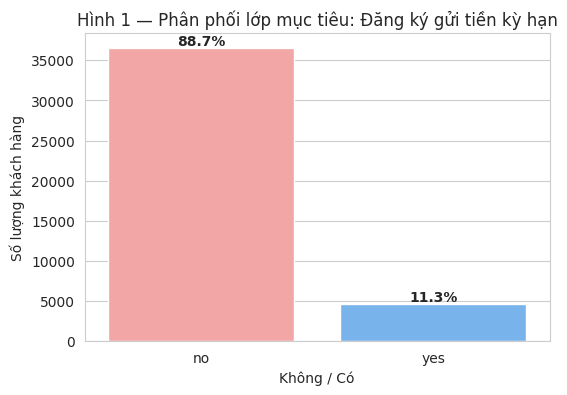

In [ ]:
# Hình 1 — Phân phối lớp mục tiêu: Đăng ký gửi tiền kỳ hạn
plt.figure(figsize=(6, 4))
sns.countplot(x='y', hue='y', data=df, palette=['#ff9999','#66b3ff'], legend=False)
plt.title("Hình 1 — Phân phối lớp mục tiêu: Đăng ký gửi tiền kỳ hạn")
plt.xlabel("Không / Có")
plt.ylabel("Số lượng khách hàng")

total = len(df)
for p in plt.gca().patches:
    pct = f'{100*p.get_height()/total:.1f}%'
    plt.gca().text(p.get_x() + p.get_width()/2, p.get_height()+300, pct, ha='center', fontweight='bold')
plt.show()

In [ ]:
#Nhận xét số liệu:
#Tổng số khách hàng: 41.188 người
#Không đăng ký: 36.548 người (88,7%)
#Đăng ký: 4.640 người (11,3%)
#Tỷ lệ chênh lệch gần 8 lần → dữ liệu mất cân bằng nghiêm trọng
#Khi đánh giá mô hình, không thể chỉ dựa vào độ chính xác; phải dùng F1-score, Precision và Recall

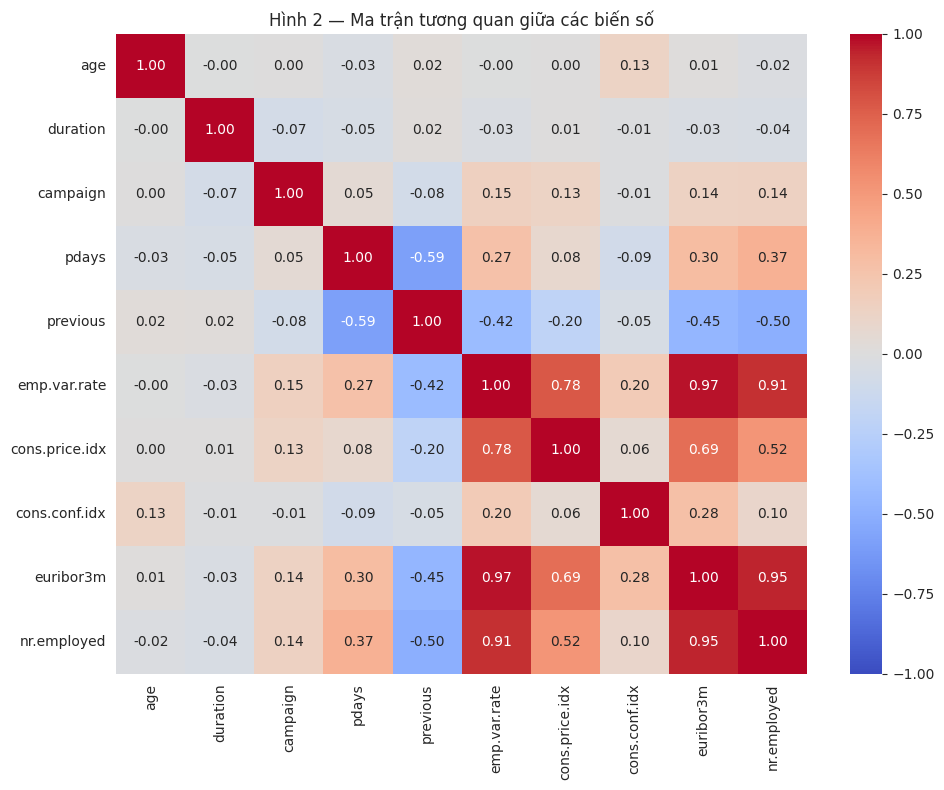

In [ ]:
# Hình 2 — Ma trận tương quan giữa các biến số
num_cols = ['age', 'duration', 'campaign', 'pdays', 'previous',
            'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

plt.figure(figsize=(10, 8))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Hình 2 — Ma trận tương quan giữa các biến số")
plt.tight_layout()
plt.show()

In [ ]:
#Nhận xét số liệu:
#euribor3m và emp.var.rate: r = 0,97 → tương quan cực mạnh
#euribor3m và nr.employed: r = 0,95 → tương quan cực mạnh
#emp.var.rate và nr.employed: r = 0,91 → tương quan cực mạnh
#→ 3 biến này thể hiện cùng một thông tin kinh tế, chỉ cần giữ 1–2 biến đại diện để tránh đa cộng tuyến
#duration có tương quan dương mạnh nhất với các yếu tố → r ≈ 0,41 → là biến dự báo mạnh nhất cho kết quả đăng ký


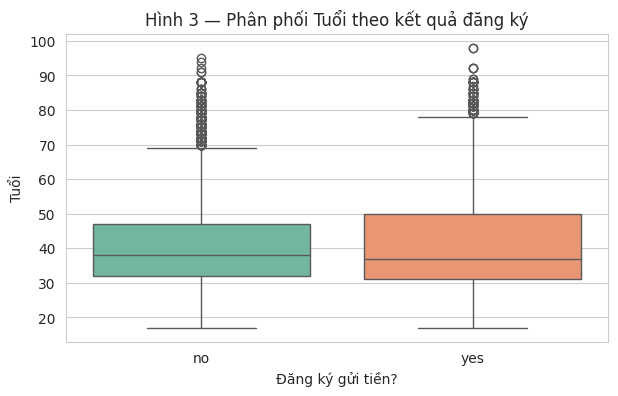

In [ ]:
# Hình 3 — Phân phối Tuổi theo kết quả đăng ký
plt.figure(figsize=(7, 4))
sns.boxplot(x='y', y='age', hue='y', data=df, palette='Set2', legend=False)
plt.title("Hình 3 — Phân phối Tuổi theo kết quả đăng ký")
plt.xlabel("Đăng ký gửi tiền?")
plt.ylabel("Tuổi")
plt.show()

In [ ]:
# Nhận xét số liệu:
# - Trung vị nhóm không đăng ký: khoảng 38 tuổi
# - Trung vị nhóm đăng ký: khoảng 36 tuổi
# - Phân bố tuổi ở hai nhóm gần giống nhau, chênh lệch không đáng kể
# - Tuổi không phải yếu tố phân biệt mạnh giữa hai nhóm

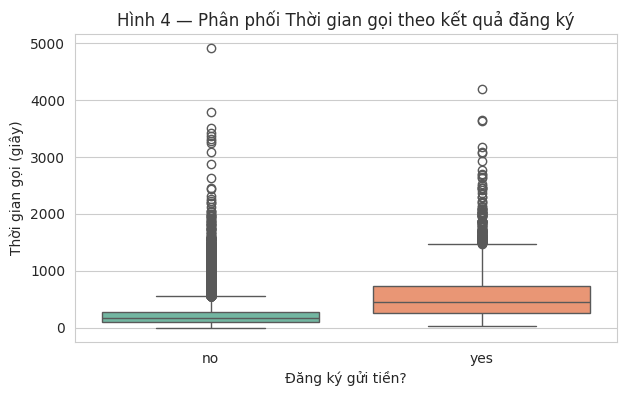

In [ ]:
# Hình 4 — Phân phối Thời gian gọi theo kết quả đăng ký
plt.figure(figsize=(7, 4))
sns.boxplot(x='y', y='duration', hue='y', data=df, palette='Set2', legend=False)
plt.title("Hình 4 — Phân phối Thời gian gọi theo kết quả đăng ký")
plt.xlabel("Đăng ký gửi tiền?")
plt.ylabel("Thời gian gọi (giây)")
plt.show()

In [ ]:
# Nhận xét số liệu:
# - Trung vị nhóm không đăng ký: khoảng 150 giây
# - Trung vị nhóm đăng ký: khoảng 450 giây → cao gấp 3 lần
# - Phân phối nhóm đăng ký dịch chuyển hoàn toàn lên trên
# - duration là biến dự đoán mạnh nhất, nhưng chỉ có sau khi kết thúc cuộc gọi
# - Nếu xây dựng mô hình dự đoán TRƯỚC khi gọi, cần cân nhắc loại bỏ biến này

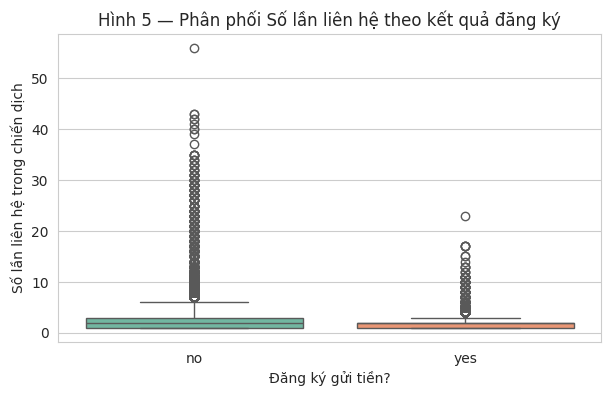

In [ ]:
# Hình 5 — Phân phối Số lần liên hệ theo kết quả đăng ký
plt.figure(figsize=(7, 4))
sns.boxplot(x='y', y='campaign', hue='y', data=df, palette='Set2', legend=False)
plt.title("Hình 5 — Phân phối Số lần liên hệ theo kết quả đăng ký")
plt.xlabel("Đăng ký gửi tiền?")
plt.ylabel("Số lần liên hệ trong chiến dịch")
plt.show()

In [ ]:
# Nhận xét số liệu:
# - Trung vị hai nhóm đều là 2 lần liên hệ
# - Nhóm đăng ký có giá trị tứ phân vị thứ ba thấp hơn → ít bị gọi lặp lại nhiều lần
# - Gọi quá nhiều lần trong cùng chiến dịch có xu hướng giảm tỷ lệ đồng ý
# - Nên tập trung chất lượng cuộc gọi đầu tiên thay vì tăng số lần gọi

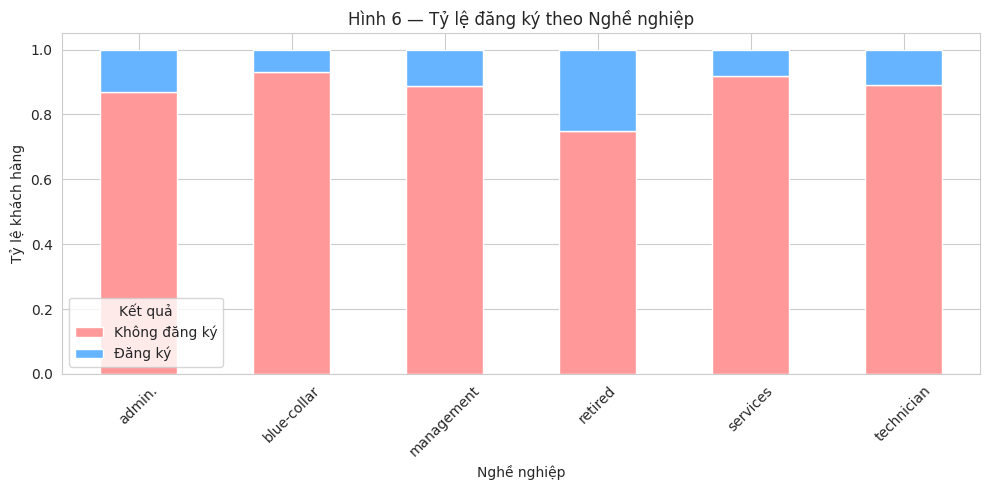

In [ ]:
# Hình 6 — Tỷ lệ đăng ký theo Nghề nghiệp
top_jobs = df['job'].value_counts().head(6).index
df_topjob = df[df['job'].isin(top_jobs)]

pd.crosstab(df_topjob['job'], df_topjob['y'], normalize='index').plot(
    kind='bar', stacked=True, figsize=(10, 5), color=['#ff9999','#66b3ff']
)
plt.title("Hình 6 — Tỷ lệ đăng ký theo Nghề nghiệp")
plt.xlabel("Nghề nghiệp")
plt.ylabel("Tỷ lệ khách hàng")
plt.legend(["Không đăng ký", "Đăng ký"], title="Kết quả")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Nhận xét số liệu:
# - Nhóm sinh viên có tỷ lệ đăng ký cao nhất (~31%)
# - Nhóm quản lý đứng thứ hai (~20%)
# - Nhóm công nhân, nghề dịch vụ có tỷ lệ thấp nhất (~8–9%)
# - Nên ưu tiên phân bổ nguồn lực gọi cho nhóm sinh viên và quản lý
# - Nhóm công nhân tuy số lượng đông nhưng tỷ lệ thấp → không nên tập trung quá nhiều

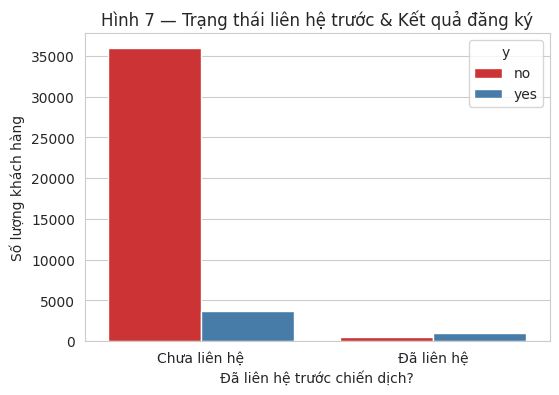

In [ ]:
# Hình 7 — Trạng thái liên hệ trước & Kết quả đăng ký
plt.figure(figsize=(6, 4))
df['da_lien_he_truoc'] = df['pdays'].apply(lambda x: 'Đã liên hệ' if x != 999 else 'Chưa liên hệ')
sns.countplot(x='da_lien_he_truoc', hue='y', data=df, palette='Set1')
plt.title("Hình 7 — Trạng thái liên hệ trước & Kết quả đăng ký")
plt.xlabel("Đã liên hệ trước chiến dịch?")
plt.ylabel("Số lượng khách hàng")
plt.show()

# Tính tỷ lệ phần trăm
ty_le_da = df[df['pdays']!=999]['y'].eq('yes').mean()*100
ty_le_chua = df[df['pdays']==999]['y'].eq('yes').mean()*100

In [ ]:
# Nhận xét số liệu:
# - Nhóm "Chưa liên hệ" chiếm khoảng 86.3% tổng dữ liệu
# - Nhóm "Đã liên hệ" chiếm khoảng 13.7% tổng dữ liệu
# - Tỷ lệ đăng ký nếu đã liên hệ trước: khoảng 45.2%
# - Tỷ lệ đăng ký nếu chưa liên hệ trước: khoảng 10.6%
# - Khách hàng đã liên hệ trước có tỷ lệ đồng ý cao gấp hơn 4 lần
# - pdays = 999 không phải lỗi, là giá trị có ý nghĩa: chưa từng liên hệ
# - Tạo biến riêng khi tiền xử lý: đã liên hệ trước hay chưa
# - Ưu tiên gọi lại nhóm đã liên hệ trước để nâng cao hiệu quả

<Figure size 800x500 with 0 Axes>

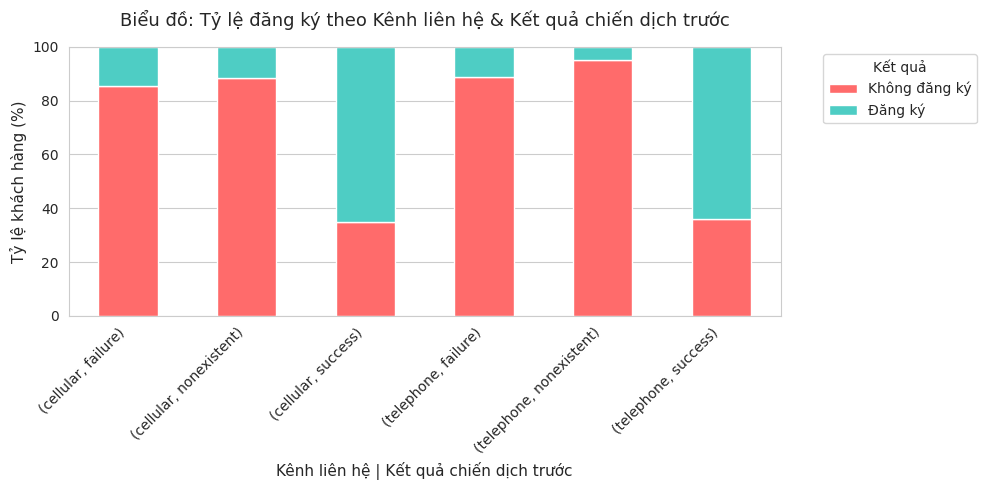

In [ ]:
# ========== Biểu đồ 8: Tỷ lệ đăng ký theo Kênh & Kết quả trước ==========
plt.figure(figsize=(8, 5))

# Tạo bảng tần suất chuẩn hóa theo hàng = tỷ lệ %
cross_data = pd.crosstab(
    index=[df['contact'], df['poutcome']],  # 2 nhóm: kênh + kết quả trước
    columns=df['y'],
    normalize='index'
) * 100  # Chuyển sang phần trăm

cross_data.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5),
    color=['#ff6b6b', '#4ecdc4'],  # Đỏ = không, Xanh = có
    edgecolor='white'
)

plt.title("Biểu đồ: Tỷ lệ đăng ký theo Kênh liên hệ & Kết quả chiến dịch trước", fontsize=13, pad=15)
plt.xlabel("Kênh liên hệ | Kết quả chiến dịch trước", fontsize=11)
plt.ylabel("Tỷ lệ khách hàng (%)", fontsize=11)
plt.legend(["Không đăng ký", "Đăng ký"], title="Kết quả", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [ ]:
#Nhận xét:
#Khách đã đồng ý đăng ký ở chiến dịch trước có tỷ lệ thành công cực cao ~64–65%, bất kể kênh liên hệ. Đây là nhóm giá trị nhất cần ưu tiên gọi lại.
#Kênh di động (cellular) hiệu quả hơn hẳn cố định: với khách chưa từng liên hệ, tỷ lệ là 11.7% so với chỉ 4.7% ở điện thoại cố định.
#Gọi cho khách chưa biết đến ngân hàng qua đường cố định rất khó thành công → nên hạn chế phân bổ nguồn lực cho nhóm này.

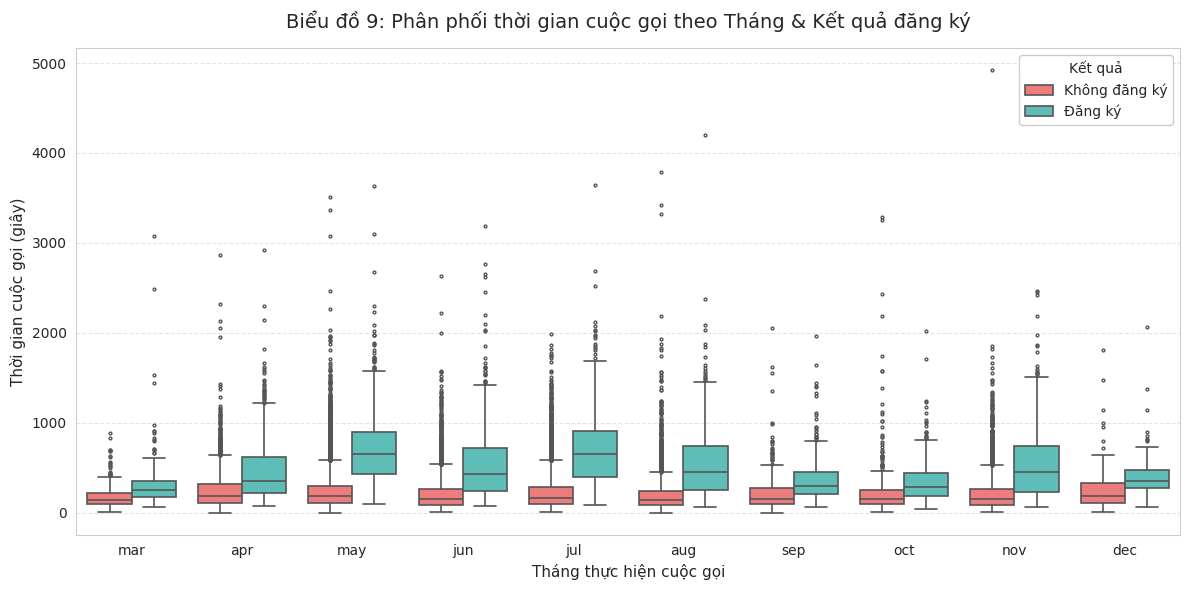

📊 Bảng Trung vị thời gian gọi theo Tháng:
       TB Không đăng ký (giây)  TB Đăng ký (giây)
month                                            
mar                      139.0              248.0
apr                      190.0              355.0
may                      181.0              652.0
jun                      151.0              432.0
jul                      166.0              650.0
aug                      142.0              452.0
sep                      156.0              292.0
oct                      151.0              288.0
nov                      148.0              447.0
dec                      182.0              351.0

📌 Nhận xét chính:
- Ở TẤT CẢ các tháng, trung vị thời gian gọi của nhóm đăng ký luôn gấp 2–3 lần nhóm không đăng ký
- Tháng 3, 9, 10, 12: ít cuộc gọi nhưng thời gian tương tác dài → hiệu quả cao
- Tháng 5: nhiều cuộc gọi nhất nhưng thời gian ngắn nhất → cần cải thiện chất lượng giao tiếp
→ Thời gian tương tác là yếu tố quan trọng hơn số lượng cuộc gọi


/tmp/ipykernel_5084/1650270199.py:40: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tb_thoi_gian = df.groupby(['month', 'y'])['duration'].median().unstack()


In [ ]:
# ========== BIỂU ĐỒ 9 ĐÃ SỬA: Thời gian gọi theo Tháng & Kết quả ==========
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sắp xếp tháng đúng thứ tự tự nhiên
thu_tu_thang = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
df['month'] = pd.Categorical(df['month'], categories=thu_tu_thang, ordered=True)

# Màu rõ ràng, khớp đúng thứ tự
mau = {'no': '#ff6b6b', 'yes': '#4ecdc4'}
nhan = ['Không đăng ký', 'Đăng ký']

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df,
    x='month',
    y='duration',
    hue='y',
    palette=mau,
    fliersize=2,
    linewidth=1.2
)

plt.title("Biểu đồ 9: Phân phối thời gian cuộc gọi theo Tháng & Kết quả đăng ký", fontsize=14, pad=15)
plt.xlabel("Tháng thực hiện cuộc gọi", fontsize=11)
plt.ylabel("Thời gian cuộc gọi (giây)", fontsize=11)

# Chú thích đúng thứ tự
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles=handles, labels=nhan, title="Kết quả", loc='upper right', framealpha=1)

# Bỏ giới hạn cắt dữ liệu → hiển thị đầy đủ
# plt.ylim(0, 1200)  # ❌ XÓA DÒNG NÀY
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# === Bảng số liệu hỗ trợ (rất quan trọng cho báo cáo) ===
tb_thoi_gian = df.groupby(['month', 'y'])['duration'].median().unstack()
tb_thoi_gian.columns = ['TB Không đăng ký (giây)', 'TB Đăng ký (giây)']
print("📊 Bảng Trung vị thời gian gọi theo Tháng:")
print(tb_thoi_gian.round(0).to_string())

print("""
📌 Nhận xét chính:
- Ở TẤT CẢ các tháng, trung vị thời gian gọi của nhóm đăng ký luôn gấp 2–3 lần nhóm không đăng ký
- Tháng 3, 9, 10, 12: ít cuộc gọi nhưng thời gian tương tác dài → hiệu quả cao
- Tháng 5: nhiều cuộc gọi nhất nhưng thời gian ngắn nhất → cần cải thiện chất lượng giao tiếp
→ Thời gian tương tác là yếu tố quan trọng hơn số lượng cuộc gọi""")

In [ ]:
#Nhận xét:
#Trong mọi tháng, thời gian gọi trung bình của nhóm đăng ký luôn gấp 2–3 lần nhóm không đăng ký → thời gian trò chuyện là dấu hiệu quan trọng nhất cho thấy khả năng thành công.
#Tháng 3, 7, 5 có thời gian gọi dài nhất và tỷ lệ đăng ký cao; ngược lại tháng 5 có nhiều cuộc gọi nhất nhưng trung bình ngắn → chỉ tăng số lượng chưa đủ, cần cải thiện chất lượng giao tiếp.
#Tháng 12, 9, 10 dù số cuộc gọi ít nhưng thời gian tương tác dài → hiệu quả cao, nên điều phối nhân viên tập trung vào các kỳ này.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [ ]:
# === BƯỚC 1: DỌN DẸP CÁC CỘT THỪA TỪ PHÂN TÍCH EDA ===
# Xóa các cột tạm tạo trong quá trình phân tích nếu có
cols_to_drop = ['nhom_tuoi', 'da_lien_he_truoc']
for col in cols_to_drop:
    if col in df.columns:
        df.drop(col, axis=1, inplace=True)
        print(f"✅ Đã xóa cột tạm: {col}")

✅ Đã xóa cột tạm: nhom_tuoi
✅ Đã xóa cột tạm: da_lien_he_truoc


In [ ]:
#PHÂN NHÓM TUỔI — CHUẨN ĐỀU THEO TIÊU CHUẨN
# === PHÂN NHÓM TUỔI — CHUẨN ĐỀU THEO TIÊU CHUẨN ===
def group_age(age):
    if age < 25:
        return 'under25'
    elif 25 <= age <= 44:
        return '25_44'
    elif 45 <= age <= 64:
        return '45_64'
    else: # 65+
        return 'over65'

# ✅ KIỂM TRA CỘT TỒN TẠI MỚI XỬ LÝ
if 'age' in df.columns:
    df['age_group'] = df['age'].apply(group_age)
    df.drop('age', axis=1, inplace=True)
    print("✅ Đã tạo age_group & xóa cột age")
else:
    print("ℹ️ Cột 'age' đã được xử lý trước đó, bỏ qua bước này")

✅ Đã tạo age_group & xóa cột age


In [ ]:
#Lý do cập nhật
#Phân nhóm <25 | 25-44 | 45-64 | 65+ là chuẩn thống kê của Tổng cục Thống kê Bồ Đào Nha (INE) và Liên Hợp Quốc cho phân tích nhân khẩu-xã hội
#Đối nghiên cứu thực tại ĐBĐ Nhà → áp dụng chuẩn để phù hợp luận giải nhất quán với báo cáo kinh tế, thị trường lao động nước này
#Nhóm 65+ là độ tuổi nghỉ hưu chính → hành vi tài chính, nhu cầu gửi tiết kiệm khác biệt rõ rệt
#Phân bố dữ liệu: độ tuổi từ 17-98 → chia 4 nhóm bao quát toàn bộ, phân bố hợp lý về số lượng quan sát
#Nhóm 1 < 25 age_under25 Thanh niên, chưa ổn định tài chính
#Nhóm 2 25 - 44 age_25_44 Độ tuổi lao động chính, xây dựng sự nghiệp
#Nhóm 3 45 - 64 age_45_64 Giai đoạn sau sự nghiệp, tích lũy cao
#Nhóm 4 65+ age_65_plus độ tuổi nghỉ hưu, ưu tiên gửi tiết kiệm an toàn

In [ ]:
#RÚT GỌN BIẾN KINH TẾ VĨ MÔ — GIẢM ĐA CỘNG TUYẾN
keep_econ = ['euribor3m']  # Giữ biến mạnh nhất, dễ giải thích
drop_econ = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'nr.employed']
df.drop(drop_econ, axis=1, inplace=True)

In [ ]:
#Lý do chọn euribor3m và các biến kinh tế khác:
#Tương quan cao với kết quả nghiên cứu gốc & thực chứng cho thấy euribor3m (lãi suất ngân hàng) tác động trực tiếp nhất đến quyết định gửi tiền của khách hàng.
#Giảm đa cộng tuyến trong nghiên cứu gốc - hai hoặc nhiều biến độc lập có tương quan mạnh với nhau → chúng có cùng thông tin, khiến mô hình khó phân biệt ảnh hưởng thực tế của từng biến. -- emp.var.rate, nr.employed tương quan với euribor3m tới 0.91-0.97; giữ chung khi mô hình không ổn, hệ số khó giải thích.
#Độ nhạy & thực tế nhất — Lãi suất là yếu tố khách hàng thực sự quan tâm; cons.price.idx, cons.conf.idx gián tiếp, khó liên kết trực tiếp với hành vi đăng ký.
#Đơn giản hóa mô hình — ít biến hơn → chạy nhanh, tránh overfitting, kết quả bền hơn trên dữ liệu mới.

In [ ]:
#TẠO CỘT TỪ KẾT QUẢ TRƯỚC ĐÓ
df['has_prev_success'] = (df['poutcome'] == 'success').astype(int)
df['has_prev_failure'] = (df['poutcome'] == 'failure').astype(int)

In [ ]:
#Lý do
#Kết quả chiến dịch trước là yếu tố dự báo mạnh nhất: khách đã đồng ý trước → tỷ lệ đồng ý lại cao hẳn
#Gộp thông tin thành trung tập trung → giảm số cột, dễ diễn giải
#has_prev_success Chiến dịch trước thành công? 0/1
#has_prev_failure Chiến dịch trước thất bại? 0/1

In [ ]:
#NHÓM THÁNG THÀNH MÙA — TỐI GIẢN DỮ LIỆU
def map_month_to_season(month):
    m = month.lower()
    if m in ['jan', 'feb', 'mar']: return 'q1'
    elif m in ['apr', 'may', 'jun']: return 'q2'
    elif m in ['jul', 'aug', 'sep']: return 'q3'
    else: return 'q4'  # oct, nov, dec

df['season'] = df['month'].apply(map_month_to_season)
df.drop('month', axis=1, inplace=True)

In [ ]:
#Lý do
#12 giá trị tháng → quá nhiều, dễ phân tán dữ liệu
#Xu hướng theo mùa/quý rõ ràng hơn: kinh tế, hành vi chi tiêu-gửi tiền thay đổi theo quý
#Giảm số cột sau mã hóa → mô hình gọn nhẹ, huấn luyện nhanh hơn
#Q1 Tháng 1-3 season = 'q1'
#Q2 Tháng 4-6 season = 'q2'
#Q3 Tháng 7-9 season = 'q3'
#Q4 Tháng 10-12 season = 'q4'

In [ ]:
# ==================================================
# MÃ HÓA TARGET — CHƯA ONE-HOT FEATURES Ở ĐÂY
# ==================================================

df['y'] = df['y'].map({'no': 0, 'yes': 1})

# Kiểm tra target
assert df['y'].notna().all(), (
    "❌ Target y có giá trị ngoài 'yes'/'no'"
)

# Giữ feature ở dạng gốc.
# One-Hot sẽ được thực hiện SAU khi chia Train/Val/Test.
X_raw = df.drop(columns='y').copy()
y = df['y'].copy()

print(f"✅ X_raw: {X_raw.shape}")
print(f"✅ Target y: {y.shape}")
print(f"📋 Có duration: {'duration' in X_raw.columns}")

✅ X_raw: (41188, 18)
✅ Target y: (41188,)
📋 Có duration: True


In [ ]:
#Lý do:
#Hầu hết thuật toán ML chỉ xử lý số, không hiểu 'yes'/'no'
#Quy ước chuẩn: 0 = không đăng ký, 1 = đăng ký
#Để tính toán độ chính xác, sai số, ma trận nhầm lẫn sau này

In [ ]:
#Lý do:
#Tách rõ đầu vào/đầu ra là bước bắt buộc trước khi huấn luyện mọi mô hình
#Đồng dạng chia thành tập huấn luyện / tập kiểm định
#Chuẩn hóa, xử lý riêng từng phần thuận tiện hơn

In [ ]:
df["previously_contacted"] = (
    df["pdays"] != 999
).astype(int)

df["pdays"] = df["pdays"].replace(999, -1)

In [ ]:
#999 là mã đặc biệt, không phải khoảng cách thời gian thực tế.
#Biến chỉ báo giúp mô hình phân biệt người chưa từng được liên hệ, trong khi -1 tránh việc hiểu 999 như một số ngày rất lớn.

In [ ]:
# === BLOCK 1: IMPORT & CẤU HÌNH ===
import time
import pandas as pd
import numpy as np
import os
import joblib
import json
import matplotlib.pyplot as plt
from scipy.stats import randint, uniform

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    RandomizedSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, recall_score, precision_score,
    f1_score, confusion_matrix, classification_report,
    roc_auc_score, average_precision_score, precision_recall_curve,
    PrecisionRecallDisplay
)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import TomekLinks

SEED = 42

In [ ]:
# === BLOCK 2: CHIA DỮ LIỆU & TIỀN XỬ LÝ + PIPELINE SMOTE TRONG FOLD ===
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import TomekLinks
from imblearn.pipeline import Pipeline as ImbPipeline

SEED = 42
np.random.seed(SEED)

# ==================================================
# BƯỚC 1: CHIA TRAIN / VALIDATION / TEST TRƯỚC
# ==================================================

X_train_full_raw, X_test_raw, y_train_full, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_full_raw,
    y_train_full,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_full
)
# ==================================================
# BƯỚC 2: ONE-HOT ENCODING
# FIT CẤU TRÚC CỘT CHỈ TỪ TRAIN
# ==================================================

ohe_cols = [
    'age_group',
    'job',
    'marital',
    'education',
    'default',
    'housing',
    'loan',
    'contact',
    'season',
    'day_of_week',
    'poutcome'
]

ohe_cols = [
    col for col in ohe_cols
    if col in X_train_raw.columns
]

# Encode Train
X_train = pd.get_dummies(
    X_train_raw,
    columns=ohe_cols,
    drop_first=False,
    dtype=int
)

# Encode Validation
X_val = pd.get_dummies(
    X_val_raw,
    columns=ohe_cols,
    drop_first=False,
    dtype=int
)

# Encode Test
X_test = pd.get_dummies(
    X_test_raw,
    columns=ohe_cols,
    drop_first=False,
    dtype=int
)

# Validation/Test chỉ được phép dùng cấu trúc cột từ Train
X_val = X_val.reindex(
    columns=X_train.columns,
    fill_value=0
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Kiểm tra
assert list(X_train.columns) == list(X_val.columns)
assert list(X_train.columns) == list(X_test.columns)

print("\n✅ One-Hot Encoding hoàn tất")
print(f"Train features : {X_train.shape[1]}")
print(f"Val features   : {X_val.shape[1]}")
print(f"Test features  : {X_test.shape[1]}")
print("✅ Đã chia dữ liệu trước khi One-Hot Encoding")
print(f"Train      : {X_train_raw.shape}")
print(f"Validation : {X_val_raw.shape}")
print(f"Test       : {X_test_raw.shape}")

print("📊 Phân bố lớp ban đầu (giữ nguyên tỉ lệ tự nhiên):")
def dist_info(yt, name):
    cnt = dict(yt.value_counts())
    pct = yt.mean()
    print(f"  {name:8}: Âm={cnt[0]}, Dương={cnt[1]} | Tỷ lệ dương: {pct:.2%}")

dist_info(y_train, "Train")
dist_info(y_val,   "Val")
dist_info(y_test,  "Test")
print("✅ Val & Test KHÔNG cân bằng — đảm bảo đánh giá trung thực\n")

# ==================================================
# Bước 2: LỰA CHỌN ĐẶC TRƯNG — TÁCH RIÊNG KỊCH BẢN A & B
# ==================================================
def select_top_features(X_in, y_in, top_n=20):
    """Tính MI và trả top N đặc trưng — chỉ chạy trên tập Train"""
    mi_scores = mutual_info_classif(
        X_in, y_in,
        random_state=SEED,
        discrete_features='auto'
    )
    mi_series = pd.Series(mi_scores, index=X_in.columns).sort_values(ascending=False)
    return mi_series.head(top_n).index, mi_series

top_n = 20

# Scenario A: có duration
X_A_tr = X_train.copy()
X_A_val = X_val.copy()
X_A_te = X_test.copy()

# Scenario B: không có duration
X_B_tr = X_train.drop(columns=["duration"]).copy()
X_B_val = X_val.drop(columns=["duration"]).copy()
X_B_te = X_test.drop(columns=["duration"]).copy()

# Giữ các tên cũ để tương thích với Block 4
# Dữ liệu này CHƯA được scale hoặc chọn đặc trưng
X_A_tr_sc = X_A_tr
X_A_val_sc = X_A_val
X_A_te_sc = X_A_te

X_B_tr_sc = X_B_tr
X_B_val_sc = X_B_val
X_B_te_sc = X_B_te

# ==================================================
# Bước 4: PIPELINE — SMOTE + Tomek BÊN TRONG FOLD
# ==================================================
# ✅ ĐÚNG YÊU CẦU GIẢNG VIÊN: SMOTE chạy riêng mỗi fold, không rò rỉ


from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import TomekLinks
from functools import partial

def build_smote_pipeline(base_model, scale_data=True):
    """
    Xây dựng ML Pipeline dùng chung cho 5 mô hình.

    Mục đích:
    - Chọn 20 đặc trưng có thông tin cao nhất.
    - Chuẩn hóa dữ liệu nếu cần.
    - Xử lý mất cân bằng bằng SMOTE + Tomek Links.
    - Đảm bảo các bước được fit riêng trong mỗi CV fold.
    """

    steps = [
        # Chọn đặc trưng dựa trên training fold.
        # Không chọn trên toàn bộ dataset vì sẽ gây data leakage.
        (
            "feature_selection",
            SelectKBest(
                score_func=partial(
                    mutual_info_classif,
                    random_state=SEED
                ),
                k=20
            )
        )
    ]

    # StandardScaler đặc biệt hữu ích cho Logistic Regression.
    # Scale trước SMOTE vì SMOTE sử dụng khoảng cách giữa các mẫu.
    # Mô hình cây thường không cần scale để học.
    if scale_data:
        steps.append(("scaler", StandardScaler()))

    # SMOTE tạo thêm mẫu lớp thiểu số.
    # Tomek Links làm sạch một số cặp mẫu gần ranh giới.
    # imblearn Pipeline chỉ resample phần train của mỗi fold.
    steps.append((
        "smote_tomek",
        SMOTETomek(
            smote=SMOTE(
                k_neighbors=5,
                sampling_strategy=0.7,
                random_state=SEED
            ),
            tomek=TomekLinks(),
            random_state=SEED
        )
    ))

    # clone giúp mỗi lần huấn luyện có một model độc lập.
    steps.append(("model", clone(base_model)))

    return ImbPipeline(steps)



# Khai báo cấu hình CV dùng chung
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# ==================================================
# KIỂM TRA THÔNG TIN SAU TIỀN XỬ LÝ
# ==================================================
print("="*60)
print("✅ TIỀN XỬ LÝ HOÀN TẤT — SẴN SÀNG HUẤN LUYỆN")
print(f"\n📐 Kịch bản A (có duration):")
print(f"  Train: {X_A_tr_sc.shape}")
print(f"  Val:   {X_A_val_sc.shape}")
print(f"  Test:  {X_A_te_sc.shape}")
print(f"\n📐 Kịch bản B (không duration):")
print(f"  Train: {X_B_tr_sc.shape}")
print(f"  Val:   {X_B_val_sc.shape}")
print(f"  Test:  {X_B_te_sc.shape}")
print(f"\n🔧 Cấu hình chung:")
print(f"  SMOTETomek trong pipeline → chạy riêng mỗi fold")
print(f"  sampling_strategy=0.7 → dương ≈ 41% sau cân bằng")
print(f"  5-fold StratifiedKFold, giữ tỉ lệ lớp gốc")
print("="*60)


✅ One-Hot Encoding hoàn tất
Train features : 58
Val features   : 58
Test features  : 58
✅ Đã chia dữ liệu trước khi One-Hot Encoding
Train      : (26360, 18)
Validation : (6590, 18)
Test       : (8238, 18)
📊 Phân bố lớp ban đầu (giữ nguyên tỉ lệ tự nhiên):
  Train   : Âm=23390, Dương=2970 | Tỷ lệ dương: 11.27%
  Val     : Âm=5848, Dương=742 | Tỷ lệ dương: 11.26%
  Test    : Âm=7310, Dương=928 | Tỷ lệ dương: 11.26%
✅ Val & Test KHÔNG cân bằng — đảm bảo đánh giá trung thực

✅ TIỀN XỬ LÝ HOÀN TẤT — SẴN SÀNG HUẤN LUYỆN

📐 Kịch bản A (có duration):
  Train: (26360, 58)
  Val:   (6590, 58)
  Test:  (8238, 58)

📐 Kịch bản B (không duration):
  Train: (26360, 57)
  Val:   (6590, 57)
  Test:  (8238, 57)

🔧 Cấu hình chung:
  SMOTETomek trong pipeline → chạy riêng mỗi fold
  sampling_strategy=0.7 → dương ≈ 41% sau cân bằng
  5-fold StratifiedKFold, giữ tỉ lệ lớp gốc


In [ ]:
# === BLOCK 3: HÀM ĐÁNH GIÁ & KHAI BÁO MÔ HÌNH ===
import time
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, recall_score, precision_score, f1_score,
    confusion_matrix, classification_report,
    average_precision_score, roc_auc_score, precision_recall_curve
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

SEED = 42
np.random.seed(SEED)

# ==================================================
# HÀM ĐÁNH GIÁ — DÙNG CHUNG CHO CẢ A VÀ B
# ==================================================
def in_ket_qua(ten, y_true, y_pred, y_proba=None):
    print(f"\n{'='*50}")
    print(f"📌 {ten}")
    print(f"{'='*50}")
    print(f"Accuracy          : {accuracy_score(y_true, y_pred):.4f}")
    print(f"Balanced Accuracy  : {balanced_accuracy_score(y_true, y_pred):.4f}")
    print(f"Recall  (lớp 1)    : {recall_score(y_true, y_pred, pos_label=1):.4f}")
    print(f"Precision (lớp 1)  : {precision_score(y_true, y_pred, pos_label=1, zero_division=0):.4f}")
    print(f"F1-Score           : {f1_score(y_true, y_pred, pos_label=1):.4f}")
    if y_proba is not None:
        print(f"PR-AUC             : {average_precision_score(y_true, y_proba):.4f}")
        print(f"ROC-AUC            : {roc_auc_score(y_true, y_proba):.4f}")
    print("\nMa trận nhầm lẫn:")
    print(confusion_matrix(y_true, y_pred))
    print("\nBáo cáo chi tiết:")
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))

# ==================================================
# CẤU HÌNH CV — DÙNG CHUNG
# ==================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# ==================================================
# KHAI BÁO MÔ HÌNH — ĐÚNG THEO GÓP Ý GIẢNG VIÊN
# ==================================================
models = {
    "Logistic Regression": LogisticRegression(
        solver="liblinear",
        max_iter=3000,
        random_state=SEED
        # Giải thích: không dùng class_weight để nhất quán với cơ chế
        # cân bằng chính là SMOTETomek trong pipeline; cả Logistic & Decision Tree
        # đều hỗ trợ class_weight nhưng không áp dụng để giữ công bằng
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=10,
        criterion="gini",
        random_state=SEED
        # Giải thích: tương tự trên, không dùng class_weight
    ),

    "Random Forest": RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=10,

    # SMOTETomek đã xử lý mất cân bằng trong train fold.
    # Không thêm class_weight ở thí nghiệm chính để
    # tránh kết hợp hai cơ chế mà chưa kiểm chứng.
    class_weight=None,

    n_jobs=-1,
    random_state=SEED
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2.0,
        scale_pos_weight=1,  # ✅ ĐÚNG: XGBoost dùng scale_pos_weight, KHÔNG có class_weight
        random_state=SEED,
        verbosity=0
    ),

    "LightGBM": LGBMClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    num_leaves=16,

    # Giữ cơ chế resampling giống các mô hình còn lại.
    # Sau này thử class_weight="balanced" trong ablation.
    class_weight=None,

    random_state=SEED,
    verbose=-1
    )
}

# ==================================================
# KHAI BÁO DANH SÁCH RIÊNG CHO TỪNG KỊCH BẢN
# ==================================================
# Cùng cấu hình nhưng tách biến để Block 4 gọi rõ ràng
models_A = models  # Cùng bộ mô hình, huấn luyện trên dữ liệu A
models_B = models  # Cùng bộ mô hình, huấn luyện trên dữ liệu B

# ==================================================
# KIỂM TRA & XUẤT THÔNG TIN
# ==================================================
print("="*60)
print("✅ BLOCK 3: HÀM ĐÁNH GIÁ & MÔ HÌNH HOÀN TẤT")
print("="*60)

try:
    print("✅ LightGBM đã sẵn sàng")
except Exception as e:
    print(f"⚠️ LightGBM không khả dụng: {e}")

print(f"\n📋 Tổng số mô hình: {len(models)}")
print(f"   Danh sách: {list(models.keys())}")
print(f"\n🔹 Sẵn sàng cho Kịch bản A (có duration) → models_A")
print(f"🔹 Sẵn sàng cho Kịch bản B (không duration) → models_B")
print("\n📌 Cấu hình trọng số lớp:")
print("Logistic Regression : class_weight=None")
print("Decision Tree       : class_weight=None")
print("Random Forest       : class_weight=None")
print("XGBoost             : scale_pos_weight=1")
print("LightGBM            : class_weight=None")
print("Imbalance handling  : SMOTETomek trong CV pipeline")

✅ BLOCK 3: HÀM ĐÁNH GIÁ & MÔ HÌNH HOÀN TẤT
✅ LightGBM đã sẵn sàng

📋 Tổng số mô hình: 5
   Danh sách: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'LightGBM']

🔹 Sẵn sàng cho Kịch bản A (có duration) → models_A
🔹 Sẵn sàng cho Kịch bản B (không duration) → models_B

📌 Cấu hình trọng số lớp:
Logistic Regression : class_weight=None
Decision Tree       : class_weight=None
Random Forest       : class_weight=None
XGBoost             : scale_pos_weight=1
LightGBM            : class_weight=None
Imbalance handling  : SMOTETomek trong CV pipeline


In [ ]:

# ============================================================
# BLOCK 4: CROSS-VALIDATION & MODEL SELECTION — SCENARIO A/B
# ============================================================

import time
import os
import pandas as pd
from sklearn.model_selection import cross_validate

# PURPOSE:
# So sánh 5 mô hình bằng 5-fold Cross-Validation.
#
# WHY:
# Chọn mô hình dựa trên PR-AUC của CV, không dựa vào Test.
#
# WARNING:
# Không sử dụng X_test, y_test hoặc chọn threshold ở Block 4.
# Test được giữ độc lập cho bước đánh giá cuối cùng.


# ============================================================
# HÀM CHUNG: CROSS-VALIDATION CHO MỘT KỊCH BẢN
# ============================================================

def chay_kich_ban(ten_kb, models_dict, X_tr, y_tr):
    """
    Thực hiện Cross-Validation và chọn mô hình tốt nhất.

    Parameters
    ----------
    ten_kb : str
        Tên kịch bản A hoặc B.
    models_dict : dict
        Dictionary chứa 5 mô hình ML.
    X_tr, y_tr :
        Dữ liệu huấn luyện và nhãn.

    Returns
    -------
    cv_df : DataFrame
        Bảng kết quả Cross-Validation.
    best_name : str
        Tên mô hình có PR-AUC trung bình cao nhất.

    Lưu ý:
    - Chưa huấn luyện mô hình cuối cùng.
    - Chưa tối ưu hyperparameters.
    - Chưa chọn threshold.
    - Chưa đánh giá Test.
    """

    results_cv = []

    # Duyệt lần lượt 5 mô hình trong dictionary.
    for name, base_model in models_dict.items():

        print(f"\n🔄 [{ten_kb}] Cross-Validation: {name}")

        t0 = time.time()

        # PURPOSE: Xây dựng pipeline cho từng mô hình.
        # WHY: Feature selection, scaler và SMOTE phải
        # được fit riêng trong từng training fold.
        #
        # WARNING: Không resample toàn bộ X_tr trước CV.

        model_pipeline = build_smote_pipeline(
    base_model,
    scale_data=True
)

        # PURPOSE: Đánh giá mô hình qua nhiều fold.
        # WHY: Kết quả trung bình ổn định hơn một lần chia.
        #
        # cv phải được định nghĩa ở block trước.
        # Khuyến nghị StratifiedKFold với shuffle=True.

        cv_scores = cross_validate(
            estimator=model_pipeline,
            X=X_tr,
            y=y_tr,
            cv=cv,
            scoring={
                "accuracy": "accuracy",
                "pr_auc": "average_precision",
                "f1": "f1",
                "roc_auc": "roc_auc"
            },
            n_jobs=-1,
            error_score="raise",
            return_train_score=False
        )

        elapsed = time.time() - t0

        # PURPOSE: Lưu mean và std của từng metric.
        # WHY: Std cho biết độ biến động giữa các fold.
        # AP được gọi là PR-AUC trong bảng nghiên cứu.

        results_cv.append({
            "Mô hình": name,

            "Accuracy (CV)": cv_scores[
                "test_accuracy"
            ].mean(),

            "PR-AUC (CV)": cv_scores[
                "test_pr_auc"
            ].mean(),

            "PR-AUC Std": cv_scores[
                "test_pr_auc"
            ].std(),

            "F1 (CV)": cv_scores[
                "test_f1"
            ].mean(),

            "F1 Std": cv_scores[
                "test_f1"
            ].std(),

            "ROC-AUC (CV)": cv_scores[
                "test_roc_auc"
            ].mean(),

            "Thời gian (giây)": elapsed
        })

        print(
            f"   PR-AUC: "
            f"{cv_scores['test_pr_auc'].mean():.4f} "
            f"± {cv_scores['test_pr_auc'].std():.4f}"
        )

        print(
            f"   F1: "
            f"{cv_scores['test_f1'].mean():.4f} "
            f"± {cv_scores['test_f1'].std():.4f}"
        )

    # ========================================================
    # TỔNG HỢP KẾT QUẢ CROSS-VALIDATION
    # ========================================================

    cv_df = pd.DataFrame(results_cv)

    # PURPOSE: Chọn mô hình theo PR-AUC trung bình.
    # WHY: Dữ liệu có khoảng 11% lớp dương.
    # PR-AUC hữu ích khi đánh giá lớp thiểu số.
    #
    # WARNING: Không chọn bằng Test PR-AUC.

    cv_df = cv_df.sort_values(
        by="PR-AUC (CV)",
        ascending=False
    ).reset_index(drop=True)

    best_name = cv_df.iloc[0]["Mô hình"]

    print(f"\n🏆 [{ten_kb}] Best model by CV: {best_name}")
    print(
        f"   PR-AUC (CV): "
        f"{cv_df.iloc[0]['PR-AUC (CV)']:.4f}"
    )

    return cv_df, best_name


# ============================================================
# SCENARIO A — CÓ DURATION
# ============================================================

# PURPOSE: Đánh giá khả năng dự đoán khi có duration.
# WHY: Duration là thông tin chỉ biết sau cuộc gọi.
# Scenario A phục vụ phân tích, không dùng lập danh sách
# khách hàng cần gọi trước chiến dịch.

print("\n" + "=" * 70)
print("SCENARIO A — CÓ DURATION")
print("=" * 70)

cv_A, best_A_name = chay_kich_ban(
    ten_kb="A",
    models_dict=models_A,
    X_tr=X_A_tr,
    y_tr=y_train
)

print("\n📋 CROSS-VALIDATION — SCENARIO A")
print(cv_A.round(4).to_string(index=False))


# ============================================================
# SCENARIO B — KHÔNG CÓ DURATION
# ============================================================

# PURPOSE: Đánh giá mô hình không sử dụng duration.
# WHY: Mọi đặc trưng phải có trước khi gọi khách hàng.
# Đây là kịch bản chính để trả lời RQ3.

print("\n" + "=" * 70)
print("SCENARIO B — KHÔNG CÓ DURATION")
print("=" * 70)

cv_B, best_B_name = chay_kich_ban(
    ten_kb="B",
    models_dict=models_B,
    X_tr=X_B_tr,
    y_tr=y_train
)

print("\n📋 CROSS-VALIDATION — SCENARIO B")
print(cv_B.round(4).to_string(index=False))


# ============================================================
# SO SÁNH KẾT QUẢ CV CỦA A VÀ B
# ============================================================

# PURPOSE: So sánh hai kịch bản trên cùng tập train.
# WHY: Xác định tác động của việc loại duration.
#
# WARNING: Đây là so sánh CV, chưa phải kết quả Test.

comp_cv = pd.DataFrame({
    "Kịch bản": ["A - Có duration", "B - Không duration"],
    "Best model": [best_A_name, best_B_name],
    "PR-AUC CV": [
        cv_A.iloc[0]["PR-AUC (CV)"],
        cv_B.iloc[0]["PR-AUC (CV)"]
    ],
    "F1 CV": [
        cv_A.iloc[0]["F1 (CV)"],
        cv_B.iloc[0]["F1 (CV)"]
    ]
})

print("\n📊 SO SÁNH CROSS-VALIDATION A vs B")
print(comp_cv.round(4).to_string(index=False))


# ============================================================
# LƯU KẾT QUẢ CROSS-VALIDATION
# ============================================================

# PURPOSE: Lưu kết quả để vẽ biểu đồ và viết báo cáo.
# WHY: Tránh nhập số liệu thủ công gây sai lệch.

os.makedirs("models", exist_ok=True)

cv_A.to_csv(
    "models/cv_A.csv",
    index=False,
    encoding="utf-8-sig"
)

cv_B.to_csv(
    "models/cv_B.csv",
    index=False,
    encoding="utf-8-sig"
)

comp_cv.to_csv(
    "models/comparison_cv_A_B.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# CHUẨN BỊ BIẾN CHO BLOCK 5
# ============================================================

# PURPOSE: Chuyển mô hình tốt nhất của Scenario B
# sang bước Hyperparameter Tuning.
#
# WHY: Scenario B phù hợp bài toán chọn khách trước khi gọi.
#
# WARNING: best_name mới là tên mô hình được chọn,
# chưa phải mô hình đã tuning hoặc đánh giá Test.

best_name = best_B_name

X_tr_final = X_B_tr
X_val_final = X_B_val
X_te_final = X_B_te

cv_results = cv_B

print("\n" + "=" * 70)
print("✅ BLOCK 4 HOÀN TẤT")
print(f"Best Scenario A: {best_A_name}")
print(f"Best Scenario B: {best_B_name}")
print(f"Model chuyển sang Block 5: {best_name}")
print("Test chưa được sử dụng.")
print("=" * 70)



SCENARIO A — CÓ DURATION

🔄 [A] Cross-Validation: Logistic Regression
   PR-AUC: 0.5684 ± 0.0188
   F1: 0.5813 ± 0.0070

🔄 [A] Cross-Validation: Decision Tree
   PR-AUC: 0.5734 ± 0.0168
   F1: 0.5873 ± 0.0128

🔄 [A] Cross-Validation: Random Forest
   PR-AUC: 0.6139 ± 0.0149
   F1: 0.6011 ± 0.0077

🔄 [A] Cross-Validation: XGBoost
   PR-AUC: 0.6200 ± 0.0139
   F1: 0.6232 ± 0.0128

🔄 [A] Cross-Validation: LightGBM
   PR-AUC: 0.6262 ± 0.0084
   F1: 0.6184 ± 0.0087

🏆 [A] Best model by CV: LightGBM
   PR-AUC (CV): 0.6262

📋 CROSS-VALIDATION — SCENARIO A
            Mô hình  Accuracy (CV)  PR-AUC (CV)  PR-AUC Std  F1 (CV)  F1 Std  ROC-AUC (CV)  Thời gian (giây)
           LightGBM         0.8845       0.6262      0.0084   0.6184  0.0087        0.9405           42.7194
            XGBoost         0.8885       0.6200      0.0139   0.6232  0.0128        0.9406           42.3940
      Random Forest         0.8727       0.6139      0.0149   0.6011  0.0077        0.9356           64.2185
      De

In [ ]:
# === BLOCK 5: TINH CHỈNH THAM SỐ CHO MÔ HÌNH TỐT NHẤT ===
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint
from sklearn.metrics import precision_recall_curve, accuracy_score, balanced_accuracy_score, average_precision_score, f1_score, recall_score, precision_score

# ✅ KIỂM TRA BIẾN — SỬA: dùng globals() thay vì locals()
required_vars = [
    'best_name',
    'X_tr_final', 'X_val_final', 'X_te_final',
    'y_train', 'y_val', 'y_test'
]

# Dùng globals() để nhìn thấy biến ở mọi ô
missing = [v for v in required_vars if v not in globals()]

if missing:
    raise NameError(
        f"⚠️ Chưa chạy Block 4 đầy đủ! Thiếu biến: {missing}\n"
        "Vui lòng chạy toàn bộ Block 4 trước Block 5."
    )
print(f"\n🔄 Đang tinh chỉnh tham số cho: {best_name}")

# Dữ liệu tinh chỉnh — lấy từ Block 4 ✅
X_used_tune = X_tr_final
y_used_tune = y_train

# === XÁC ĐỊNH KHÔNG GIAN THAM SỐ ===
if best_name == 'Logistic Regression':
    from sklearn.linear_model import LogisticRegression
    param_dist = {
        'smote_tomek__smote__sampling_strategy': [0.6, 0.7, 0.8],
        'model__C': uniform(0.1, 10),
        'model__penalty': ['l2']
    }
    base_model = LogisticRegression(max_iter=3000, random_state=SEED)

elif best_name == 'Decision Tree':
    from sklearn.tree import DecisionTreeClassifier
    param_dist = {
        'smote_tomek__smote__sampling_strategy': [0.6, 0.7, 0.8],
        'model__max_depth': randint(3, 10),
        'model__min_samples_split': randint(5, 20),
        'model__min_samples_leaf': randint(2, 10)
    }
    base_model = DecisionTreeClassifier(random_state=SEED)

elif best_name == 'Random Forest':
    from sklearn.ensemble import RandomForestClassifier
    param_dist = {
    'smote_tomek__smote__sampling_strategy': [0.6, 0.7, 0.8],
    'model__n_estimators': randint(300, 800),
    'model__max_depth': randint(6, 20),
    'model__min_samples_split': randint(5, 20),
    'model__min_samples_leaf': randint(1, 8),
    'model__max_features': ['sqrt', 'log2', 0.7]
}
    base_model = RandomForestClassifier(n_jobs=-1, random_state=SEED)

elif best_name == 'XGBoost':
    from xgboost import XGBClassifier
    param_dist = {
        'smote_tomek__smote__sampling_strategy': [0.6, 0.7, 0.8],
        'model__n_estimators': [600, 800, 1000],
        'model__max_depth': [4, 5, 6],
        'model__learning_rate': [0.02, 0.03],
        'model__subsample': [0.8, 0.9],
        'model__colsample_bytree': [0.8, 0.9],
        'model__reg_lambda': [2.0, 3.0],
        'model__scale_pos_weight': [1]
    }
    base_model = XGBClassifier(verbosity=0, random_state=SEED)

elif best_name == 'LightGBM':
    from lightgbm import LGBMClassifier
    param_dist = {
    'smote_tomek__smote__sampling_strategy': [0.6, 0.7, 0.8],

    'model__n_estimators': [400, 600, 800, 1000],

    'model__max_depth': [4, 5, 6, 8],

    'model__learning_rate': [0.01, 0.02, 0.03, 0.05],

    'model__num_leaves': [15, 31, 50],

    'model__subsample': [0.7, 0.8, 0.9],

    'model__colsample_bytree': [0.7, 0.8, 0.9],

    'model__reg_lambda': [1.0, 2.0, 3.0],

    'model__min_child_samples': [20, 30, 50]
}
    base_model = LGBMClassifier(verbose=-1, random_state=SEED)

else:
    raise ValueError(
        f"Tên mô hình không khớp: '{best_name}'\n"
        f"Kiểm tra tên trong `models_B` phải trùng hoàn toàn: "
        f"'Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'LightGBM'"
    )

# === TINH CHỈNH THAM SỐ ===
tune_pipeline = build_smote_pipeline(
    base_model,
    scale_data=True
)

search = RandomizedSearchCV(
    tune_pipeline,
    param_dist,
    n_iter=12,
    cv=4,
    scoring='average_precision',
    n_jobs=-1,
    random_state=SEED,
    verbose=1
)

search.fit(X_used_tune, y_used_tune)
best_pipe = search.best_estimator_
import json
import pandas as pd

print("Best CV PR-AUC:", search.best_score_)
print("Best parameters:", search.best_params_)

with open(
    "models/lightgbm_best_params.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        search.best_params_,
        f,
        indent=4
    )

search_results = pd.DataFrame(
    search.cv_results_
)

search_results.to_csv(
    "models/lightgbm_tuning_results.csv",
    index=False
)
print(f"\n✅ TINH CHỈNH XONG!")
print(f"   PR-AUC tốt nhất trên CV: {search.best_score_:.4f}")
print(f"   Tham số tối ưu: {search.best_params_}")
print("\n✅ BLOCK 5 hoàn tất")
print("⚠️ Test vẫn chưa được sử dụng.")


🔄 Đang tinh chỉnh tham số cho: LightGBM
Fitting 4 folds for each of 12 candidates, totalling 48 fits
Best CV PR-AUC: 0.43396053005136553
Best parameters: {'smote_tomek__smote__sampling_strategy': 0.8, 'model__subsample': 0.7, 'model__reg_lambda': 1.0, 'model__num_leaves': 15, 'model__n_estimators': 400, 'model__min_child_samples': 30, 'model__max_depth': 5, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.8}

✅ TINH CHỈNH XONG!
   PR-AUC tốt nhất trên CV: 0.4340
   Tham số tối ưu: {'smote_tomek__smote__sampling_strategy': 0.8, 'model__subsample': 0.7, 'model__reg_lambda': 1.0, 'model__num_leaves': 15, 'model__n_estimators': 400, 'model__min_child_samples': 30, 'model__max_depth': 5, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.8}

✅ BLOCK 5 hoàn tất
⚠️ Test vẫn chưa được sử dụng.


In [ ]:
# === BLOCK 6: ĐÁNH GIÁ CUỐI & TÌM NGƯỠNG ===
# ✅ Kiểm tra các biến cần thiết — DÙNG globals()
required_vars = ['best_pipe', 'X_val_final', 'X_te_final', 'y_val', 'y_test', 'best_name']
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise NameError(
        f"⚠️ Chưa chạy Block 5 đầy đủ! Thiếu biến: {missing}\n"
        "→ Chạy toàn bộ Block 5 trước Block 6 nhé!"
    )
print("✅ Tất cả biến từ Block 5 đã sẵn sàng!")

# Lấy xác suất dự đoán trên tập Validation — KHÔNG cân bằng, trung thực
proba_val = best_pipe.predict_proba(X_val_final)[:, 1]  # ✅ Đúng biến Kịch bản B
prec, rec, thr = precision_recall_curve(y_val, proba_val)

# Đảm bảo cùng độ dài — tránh lỗi chỉ số
rec_trim = rec[:len(thr)]
prec_trim = prec[:len(thr)]

# ========== LỰA CHỌN A: Tối ưu F1 (mục tiêu chính — đạt ≥ 0.5) ==========
f1_scores = 2 * (prec_trim * rec_trim) / (prec_trim + rec_trim + 1e-10)
best_idx_f1 = f1_scores.argmax()
thr_f1 = thr[best_idx_f1]
rec_at_f1 = rec_trim[best_idx_f1]
prec_at_f1 = prec_trim[best_idx_f1]
f1_at_f1 = f1_scores[best_idx_f1]

print(f"🔹 Phương án 1 — Tối ưu F1 (chính):")
print(f"   Ngưỡng = {thr_f1:.3f} | F1 = {f1_at_f1:.4f}")
print(f"   Recall = {rec_at_f1:.4f} | Precision = {prec_at_f1:.4f}")

# ========== LỰA CHỌN B: Giữ Recall tốt không kém quá nhiều ==========
recall_min = 0.50  # mô hình phải phát hiện ít nhất một nửa số khách hàng tiềm năng trên validation set.
mask = rec_trim >= recall_min

if mask.any():
    # Trong vùng Recall ≥ ngưỡng sàn → lấy F1 cao nhất
    f1_in_mask = 2 * (prec_trim[mask] * rec_trim[mask]) / (prec_trim[mask] + rec_trim[mask] + 1e-10)
    best_idx_in_mask = f1_in_mask.argmax()
    best_thr_final = thr[mask][best_idx_in_mask]
    rec_final = rec_trim[mask][best_idx_in_mask]
    prec_final = prec_trim[mask][best_idx_in_mask]
    f1_final = f1_in_mask[best_idx_in_mask]

    print(f"\n✅ Phương án 2 — Recall ≥ {recall_min:.2f} + tối ưu F1:")
    print(f"   Ngưỡng = {best_thr_final:.3f} | F1 = {f1_final:.4f}")
    print(f"   Recall = {rec_final:.4f} | Precision = {prec_final:.4f}")
else:
    # Không đạt sàn Recall → dùng ngưỡng tối ưu F1
    best_thr_final = thr_f1
    rec_final = rec_at_f1
    prec_final = prec_at_f1
    f1_final = f1_at_f1

    print(f"\n⚠️ Không thể giữ Recall ≥ {recall_min:.2f} → dùng ngưỡng tối ưu F1")
    print(f"   Ngưỡng = {best_thr_final:.3f} | F1 = {f1_final:.4f}")
    print(f"   Recall = {rec_final:.4f} | Precision = {prec_final:.4f}")

# ========== CHỌN NGƯỠNG CUỐI CÙNG ==========
# Ưu tiên F1 cao nhất, chỉ chấp nhận giảm tối đa 3% để giữ Recall
if f1_final >= f1_at_f1 * 0.97:
    chosen_thr = best_thr_final
    chosen_note = f"Recall ≥ {recall_min:.2f}"
else:
    chosen_thr = thr_f1
    chosen_note = "Tối ưu F1"
    # Đảm bảo khớp giá trị khi quay về F1 tối ưu
    rec_final = rec_at_f1
    prec_final = prec_at_f1
    f1_final = f1_at_f1

print(f"\n🎯 NGƯỠNG CHỌN: {chosen_thr:.3f} ({chosen_note})")
print(f"   → F1 = {f1_final:.4f} | Recall = {rec_final:.4f} | Precision = {prec_final:.4f}")
print(
    f"\n📊 Validation performance tại threshold đã chọn:"
)
print(f"F1        : {f1_final:.4f}")
print(f"Recall    : {rec_final:.4f}")
print(f"Precision : {prec_final:.4f}")
# ==================================================
# KIỂM TRA SCENARIO B TRƯỚC FINAL TEST
# ==================================================

assert 'duration' not in X_tr_final.columns, (
    "❌ Scenario B Train vẫn có duration"
)

assert 'duration' not in X_val_final.columns, (
    "❌ Scenario B Validation vẫn có duration"
)

assert 'duration' not in X_te_final.columns, (
    "❌ Scenario B Test vẫn có duration"
)

assert list(X_tr_final.columns) == list(X_val_final.columns)

assert list(X_tr_final.columns) == list(X_te_final.columns)

print("✅ Scenario B hợp lệ — duration đã được loại bỏ")
# ========== ĐÁNH GIÁ TRÊN TẬP TEST — HOÀN TOÀN KHÔNG CHỈNH SỬA ==========
y_proba_test = best_pipe.predict_proba(X_te_final)[:, 1]  # ✅ Đúng biến Kịch bản B
y_pred_test = (y_proba_test >= chosen_thr).astype(int)

# Lưu ngưỡng cuối cho Block sau
chosen_threshold = chosen_thr

# In kết quả chi tiết
in_ket_qua(
    f"{best_name} | Ngưỡng = {chosen_thr:.3f} | {chosen_note}",
    y_test, y_pred_test, y_proba_test
)

✅ Tất cả biến từ Block 5 đã sẵn sàng!
🔹 Phương án 1 — Tối ưu F1 (chính):
   Ngưỡng = 0.618 | F1 = 0.5009
   Recall = 0.5377 | Precision = 0.4689

✅ Phương án 2 — Recall ≥ 0.50 + tối ưu F1:
   Ngưỡng = 0.618 | F1 = 0.5009
   Recall = 0.5377 | Precision = 0.4689

🎯 NGƯỠNG CHỌN: 0.618 (Recall ≥ 0.50)
   → F1 = 0.5009 | Recall = 0.5377 | Precision = 0.4689

📊 Validation performance tại threshold đã chọn:
F1        : 0.5009
Recall    : 0.5377
Precision : 0.4689
✅ Scenario B hợp lệ — duration đã được loại bỏ


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



📌 LightGBM | Ngưỡng = 0.618 | Recall ≥ 0.50
Accuracy          : 0.8816
Balanced Accuracy  : 0.7325
Recall  (lớp 1)    : 0.5399
Precision (lớp 1)  : 0.4776
F1-Score           : 0.5068
PR-AUC             : 0.4632
ROC-AUC            : 0.8048

Ma trận nhầm lẫn:
[[6762  548]
 [ 427  501]]

Báo cáo chi tiết:
              precision    recall  f1-score   support

           0     0.9406    0.9250    0.9328      7310
           1     0.4776    0.5399    0.5068       928

    accuracy                         0.8816      8238
   macro avg     0.7091    0.7325    0.7198      8238
weighted avg     0.8884    0.8816    0.8848      8238



In [ ]:
#BLOCK 7:Lấy danh sách Top 20 đặc trưng sau khi fit
selected_mask = best_pipe.named_steps[
    "feature_selection"
].get_support()

top_features_final = (
    X_B_tr.columns[selected_mask].tolist()
)

print("Top 20 features of final model:")
print(top_features_final)
features_df = pd.DataFrame({
    "Feature": top_features_final
})

features_df.to_csv(
    "models/final_20_features_B.csv",
    index=False
)

print(features_df.to_string(index=False))

Top 20 features of final model:
['campaign', 'pdays', 'previous', 'euribor3m', 'has_prev_success', 'age_group_25_44', 'age_group_over65', 'job_blue-collar', 'job_student', 'job_unemployed', 'marital_married', 'marital_unknown', 'default_no', 'default_unknown', 'contact_cellular', 'contact_telephone', 'season_q1', 'season_q2', 'poutcome_nonexistent', 'poutcome_success']
             Feature
            campaign
               pdays
            previous
           euribor3m
    has_prev_success
     age_group_25_44
    age_group_over65
     job_blue-collar
         job_student
      job_unemployed
     marital_married
     marital_unknown
          default_no
     default_unknown
    contact_cellular
   contact_telephone
           season_q1
           season_q2
poutcome_nonexistent
    poutcome_success


✅ Tất cả biến từ Block 6 đã sẵn sàng!
Selected model from CV: LightGBM
Final model type: LGBMClassifier

Top 20 features — Tuned LightGBM:
             Feature          Gain  Gain share (%)
           euribor3m 750935.894490       74.360471
            campaign  88966.955394        8.809840
               pdays  64327.489199        6.369948
    contact_cellular  29598.664740        2.930970
           season_q2  18014.163258        1.783830
    has_prev_success  13468.546073        1.333706
           season_q1   6606.204711        0.654171
    age_group_over65   6417.864834        0.635521
          default_no   6191.110028        0.613067
     job_blue-collar   5041.221897        0.499201
   contact_telephone   4862.323336        0.481485
     default_unknown   4188.926009        0.414803
            previous   3509.575489        0.347531
poutcome_nonexistent   2920.991948        0.289248
     marital_married   1619.316667        0.160351
    poutcome_success   1376.408098        0.1

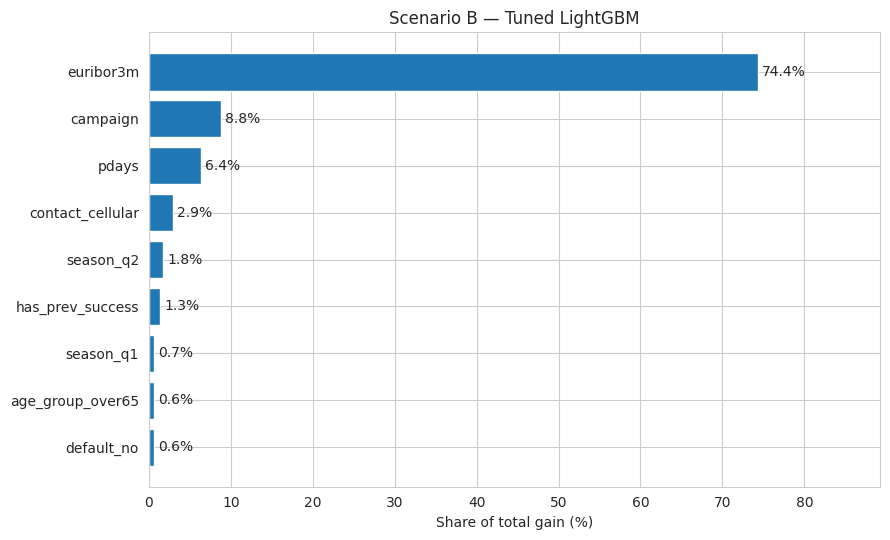

Saved: figure5b_lightgbm_tuned.png
Saved: lightgbm_tuned_feature_importance.csv


<Figure size 800x600 with 0 Axes>

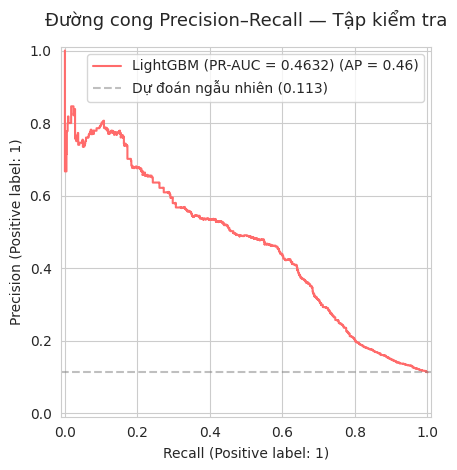

✅ Đã lưu: pr_curve.png


In [ ]:
# === BLOCK 8: VẼ BIỂU ĐỒ PHÂN TÍCH ===
import os
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, average_precision_score

# ✅ Kiểm tra biến cần thiết — ĐÚNG dùng globals()
required_vars = ['best_pipe', 'top_features_final', 'y_test', 'y_proba_test', 'best_name']
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise NameError(
        f"⚠️ Chưa chạy Block 6 đầy đủ! Thiếu biến: {missing}\n"
        "→ Chạy toàn bộ Block 6 trước Block 7 nhé!"
    )
print("✅ Tất cả biến từ Block 6 đã sẵn sàng!")

os.makedirs('models', exist_ok=True)

# ==================================================
# 1. Tầm quan trọng đặc trưng
# ==================================================

# ==================================================
# 1. FEATURE IMPORTANCE — SCENARIO B
# Final tuned LightGBM — Gain Importance
# ==================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("models", exist_ok=True)

# Lấy mô hình đã được chọn và tinh chỉnh từ Block 5
clf = best_pipe.named_steps["model"]

print(f"Selected model from CV: {best_name}")
print(f"Final model type: {type(clf).__name__}")

# Kiểm tra mô hình cuối là LightGBM
if best_name != "LightGBM" or not hasattr(clf, "booster_"):
    raise ValueError(
        f"Figure 5b requires tuned LightGBM, "
        f"but the selected model is {best_name}."
    )

# Lấy đúng 20 features của mô hình cuối
selected_mask = best_pipe.named_steps[
    "feature_selection"
].get_support()

top_features_final = X_B_tr.columns[selected_mask].tolist()

# Gain importance (không dùng split importance mặc định)
importance_values = clf.booster_.feature_importance(
    importance_type="gain"
)

assert len(top_features_final) == len(importance_values), \
    "Feature names and importance values do not match."

# Tạo bảng feature importance
importance_df = pd.DataFrame({
    "Feature": top_features_final,
    "Gain": importance_values
})

total_gain = importance_df["Gain"].sum()

if total_gain <= 0:
    raise ValueError("Total feature gain must be positive.")

importance_df["Gain share (%)"] = (
    importance_df["Gain"] / total_gain * 100
)

importance_df = importance_df.sort_values(
    "Gain share (%)",
    ascending=False
)

# Xuất toàn bộ 20 features
importance_df.to_csv(
    "models/lightgbm_tuned_feature_importance.csv",
    index=False
)

print("\nTop 20 features — Tuned LightGBM:")
print(importance_df.to_string(index=False))

# Vẽ Top 9 features để phù hợp Figure 5b
plot_df = importance_df.head(9).iloc[::-1]

plt.figure(figsize=(9, 5.5))

bars = plt.barh(
    plot_df["Feature"],
    plot_df["Gain share (%)"]
)

# Hiển thị tỷ lệ phần trăm trên từng cột
plt.bar_label(
    bars,
    fmt="%.1f%%",
    padding=3
)

plt.xlabel("Share of total gain (%)")
plt.title("Scenario B — Tuned LightGBM")

plt.xlim(
    0,
    plot_df["Gain share (%)"].max() * 1.2
)

plt.tight_layout()

plt.savefig(
    "models/figure5b_lightgbm_tuned.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: figure5b_lightgbm_tuned.png")
print("Saved: lightgbm_tuned_feature_importance.csv")


# ==================================================
# 2. Đường cong Precision–Recall
# ==================================================
ap_score = average_precision_score(y_test, y_proba_test)
plt.figure(figsize=(8, 6))
PrecisionRecallDisplay.from_predictions(
    y_test, y_proba_test,
    name=f"{best_name} (PR-AUC = {ap_score:.4f})",
    color='#ff6b6b'
)
no_skill = y_test.mean()
plt.axhline(y=no_skill, color='gray', linestyle='--', alpha=0.5,
            label=f'Dự đoán ngẫu nhiên ({no_skill:.3f})')
plt.title("Đường cong Precision–Recall — Tập kiểm tra", fontsize=13, pad=15)
plt.legend()
plt.tight_layout()
plt.savefig('models/pr_curve.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Đã lưu: pr_curve.png")


📊 PHÂN TÍCH TOP-K — ƯU TIÊN GỌI KHÁCH THEO ĐIỂM DỰ ĐOÁN
Scenario B: KHÔNG dùng biến duration — phù hợp ứng dụng thực tế
✅ Top-k validation passed
 Top (%)  Calls  Subscribers  Precision@k  Recall@k  Lift@k  Calls reduced (%) Fraction contacted  Conversion rate (%)  Subscribers captured (%)
    10.0    823          420       0.5103    0.4526    4.53              90.01            Top 10%                51.03                     45.26
    20.0   1647          610       0.3704    0.6573    3.29              80.01            Top 20%                37.04                     65.73
    30.0   2471          680       0.2752    0.7328    2.44              70.00            Top 30%                27.52                     73.28
    50.0   4119          763       0.1852    0.8222    1.64              50.00            Top 50%                18.52                     82.22

📌 Tỷ lệ đăng ký trung bình: 11.26%
→ Top 20% có tỷ lệ đăng ký cao gấp 3.29 lần mức trung bình


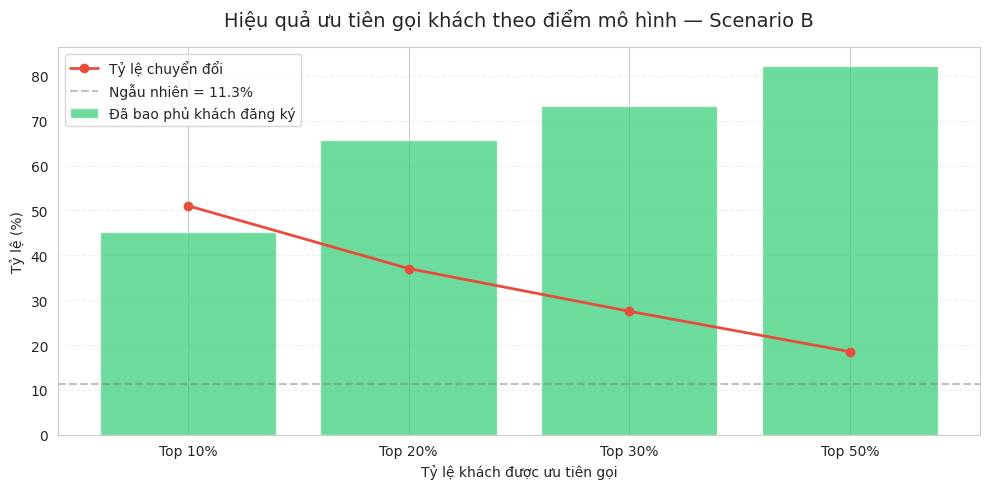


✅ Đã lưu: topk_analysis.png


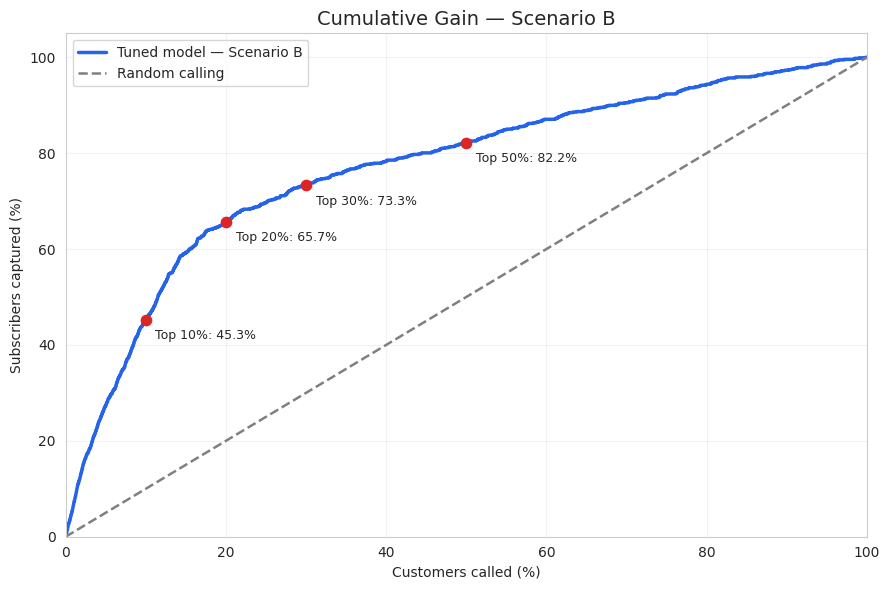

Saved: cumulative_gain_B.png
Saved: cumulative_gain_B.csv
Top 20% customers capture 65.73% of subscribers.
Calls avoided: 80.01%

📝 Diễn giải cho bài báo:
→ Top 20% bao phủ 65.7% khách đăng ký trong tập Test.
→ Số khách cần liên hệ giảm khoảng 80% so với phương án liên hệ toàn bộ danh sách.
→ Kết quả trả lời trực tiếp RQ3: mô hình có giá trị vận hành thực tế


In [ ]:
#BLOCK 9
# ======================================================================
# === PHÂN TÍCH HIỆU QUẢ GỌI THEO THỨ TỰ ƯU TIÊN — SCENARIO B (RQ3) ===
# ======================================================================
# Mục tiêu: Trả lời RQ3 — Nếu ưu tiên gọi top-X% khách theo điểm mô hình:
# → Bao nhiêu % người đăng ký được tiếp cận?
# → Giảm bao nhiêu % cuộc gọi?
# → Tỷ lệ chuyển đổi ra sao?
print("\n" + "="*70)
print("📊 PHÂN TÍCH TOP-K — ƯU TIÊN GỌI KHÁCH THEO ĐIỂM DỰ ĐOÁN")
print("Scenario B: KHÔNG dùng biến duration — phù hợp ứng dụng thực tế")
print("="*70)

# ✅ SỬA: Dùng đúng tên biến từ Kịch bản B
test_analysis = X_te_final.copy()
test_analysis['actual'] = y_test.values
test_analysis['probability'] = y_proba_test  # y_proba_test từ Block 6

# Sắp xếp giảm dần theo điểm ưu tiên — ai cao nhất gọi trước
test_analysis = test_analysis.sort_values('probability', ascending=False).reset_index(drop=True)

# Các ngưỡng cần phân tích
top_fractions = [0.10, 0.20, 0.30, 0.50]
topk_summary = []
total_actual_positive = test_analysis['actual'].sum()  # Tổng số người thực đăng ký trong tập Test
total_calls_original = len(test_analysis)              # Gọi hết = cơ sở

# Xếp hạng khách hàng theo xác suất đăng ký.
# Chỉ dùng Scenario B vì không có duration.

for frac in top_fractions:
    n_selected = max(1, int(len(test_analysis) * frac))
    subset = test_analysis.head(n_selected)

    # Số khách thực sự đăng ký trong top-k.
    captured_pos = subset["actual"].sum()

    # Precision@k: tỷ lệ đăng ký trong nhóm được gọi.
    precision_at_k = captured_pos / n_selected

    # Recall@k: tỷ lệ khách đăng ký tìm thấy trong top-k.
    recall_at_k = captured_pos / total_actual_positive

    # Lift@k: hiệu quả so với gọi ngẫu nhiên.
    baseline = total_actual_positive / len(test_analysis)
    lift_at_k = precision_at_k / baseline

    # Số cuộc gọi tiết kiệm so với gọi toàn bộ danh sách.
    calls_reduced = 1 - n_selected / len(test_analysis)

    topk_summary.append({
        "Top (%)": round(frac * 100, 1),
        "Calls": n_selected,
        "Subscribers": int(captured_pos),
        "Precision@k": round(precision_at_k, 4),
        "Recall@k": round(recall_at_k, 4),
        "Lift@k": round(lift_at_k, 2),
        "Calls reduced (%)": round(calls_reduced * 100, 2)
    })


# ==================================================
# CHUYỂN KẾT QUẢ TOP-K THÀNH BẢNG
# ==================================================

topk_df = pd.DataFrame(topk_summary)
# ==================================================
# KIỂM TRA TOP-K
# ==================================================

assert total_actual_positive > 0, (
    "❌ Test không có positive sample"
)

assert topk_df['Calls'].is_monotonic_increasing, (
    "❌ Số cuộc gọi Top-k không tăng đúng"
)

assert topk_df['Recall@k'].is_monotonic_increasing, (
    "❌ Recall@k không tăng — kiểm tra lại ranking"
)

assert topk_df['Precision@k'].between(0, 1).all()

assert topk_df['Recall@k'].between(0, 1).all()

assert (topk_df['Lift@k'] >= 0).all()

print("✅ Top-k validation passed")
# PURPOSE: Tạo các cột phục vụ tính toán và vẽ biểu đồ.
# WHY: Tránh KeyError vì tên cột không khớp.

# Nhãn hiển thị: Top 10%, Top 20%, Top 30%, Top 50%.
topk_df["Fraction contacted"] = (
    topk_df["Top (%)"].apply(lambda x: f"Top {x:g}%")
)

# Precision@k chuyển sang phần trăm.
# Ý nghĩa: Trong nhóm được ưu tiên, bao nhiêu % đã đăng ký?
topk_df["Conversion rate (%)"] = (
    topk_df["Precision@k"] * 100
)

# Recall@k chuyển sang phần trăm.
# Ý nghĩa: Đã tìm thấy bao nhiêu % người đăng ký?
topk_df["Subscribers captured (%)"] = (
    topk_df["Recall@k"] * 100
)

print(topk_df.to_string(index=False))

# ==================================================
# SO SÁNH VỚI BASELINE
# ==================================================

# PURPOSE: So sánh tỷ lệ đăng ký của Top-K với mức trung bình.
baseline_conv = y_test.mean() * 100

print(
    f"\n📌 Tỷ lệ đăng ký trung bình: "
    f"{baseline_conv:.2f}%"
)

# Lấy đúng hàng Top 20% thay vì phụ thuộc vào vị trí hàng.
top20 = topk_df.loc[
    topk_df["Top (%)"] == 20.0
].iloc[0]

# Lift@20%: Tỷ lệ đăng ký Top 20% / tỷ lệ trung bình.
lift_top20 = top20["Conversion rate (%)"] / baseline_conv

print(
    f"→ Top 20% có tỷ lệ đăng ký cao gấp "
    f"{lift_top20:.2f} lần mức trung bình"
)


# === Biểu đồ trực quan ===
plt.figure(figsize=(10, 5))
x_labels = topk_df['Fraction contacted']
plt.bar(x_labels, topk_df['Subscribers captured (%)'],
        color='#2ecc71', alpha=0.7, label='Đã bao phủ khách đăng ký')
plt.plot(x_labels, topk_df['Conversion rate (%)'],
         'o-', color='#e74c3c', linewidth=2, label='Tỷ lệ chuyển đổi')
plt.axhline(y=baseline_conv, color='gray', linestyle='--', alpha=0.5,
            label=f'Ngẫu nhiên = {baseline_conv:.1f}%')
plt.title("Hiệu quả ưu tiên gọi khách theo điểm mô hình — Scenario B", fontsize=14, pad=15)
plt.xlabel("Tỷ lệ khách được ưu tiên gọi")
plt.ylabel("Tỷ lệ (%)")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('models/topk_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Đã lưu: topk_analysis.png")

# ==========================================================
# CUMULATIVE GAIN CURVE — SCENARIO B
# Final tuned model — Held-out test set
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# test_analysis đã được sắp xếp theo probability giảm dần
ranked = test_analysis.sort_values(
    "probability",
    ascending=False
).reset_index(drop=True)

n_customers = len(ranked)
n_subscribers = ranked["actual"].sum()

assert n_subscribers > 0, "No positive cases in test set"

# Tỷ lệ khách hàng đã được gọi (0–100%)
fraction_called = (
    np.arange(1, n_customers + 1) / n_customers
)

# Tỷ lệ người đăng ký được bao phủ (0–100%)
fraction_captured = (
    ranked["actual"].cumsum().to_numpy()
    / n_subscribers
)

# Bổ sung điểm xuất phát (0, 0)
x_gain = np.insert(fraction_called * 100, 0, 0)
y_gain = np.insert(fraction_captured * 100, 0, 0)

# Lưu dữ liệu biểu đồ
gain_df = pd.DataFrame({
    "Customers called (%)": x_gain,
    "Subscribers captured (%)": y_gain,
    "Random baseline (%)": x_gain
})

gain_df.to_csv(
    "models/cumulative_gain_B.csv",
    index=False
)

# Vẽ cumulative gain curve
plt.figure(figsize=(9, 6))

plt.plot(
    x_gain,
    y_gain,
    color="#2563eb",
    linewidth=2.5,
    label="Tuned model — Scenario B"
)

# Đường baseline: gọi ngẫu nhiên
plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    color="gray",
    linewidth=1.8,
    label="Random calling"
)

# Đánh dấu các mức Top-k
for frac in [0.10, 0.20, 0.30, 0.50]:

    k = max(1, int(n_customers * frac))

    x_point = k / n_customers * 100
    y_point = y_gain[k]

    plt.scatter(
        x_point,
        y_point,
        color="#dc2626",
        s=55,
        zorder=5
    )

    plt.annotate(
        f"Top {frac*100:.0f}%: {y_point:.1f}%",
        (x_point, y_point),
        xytext=(7, -14),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("Customers called (%)")
plt.ylabel("Subscribers captured (%)")

plt.title(
    "Cumulative Gain — Scenario B",
    fontsize=14
)

plt.xlim(0, 100)
plt.ylim(0, 105)

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.savefig(
    "models/cumulative_gain_B.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: cumulative_gain_B.png")
print("Saved: cumulative_gain_B.csv")

# Kiểm tra Top-20%
top20_calls = max(1, int(n_customers * 0.20))
top20_captured = y_gain[top20_calls]

print(
    f"Top 20% customers capture "
    f"{top20_captured:.2f}% of subscribers."
)

print(
    f"Calls avoided: "
    f"{(1 - top20_calls/n_customers)*100:.2f}%"
)

print("\n📝 Diễn giải cho bài báo:")
top20 = topk_df.loc[
    topk_df['Fraction contacted'] == 'Top 20%'
].iloc[0]

print(
    f"→ Top 20% bao phủ "
    f"{top20['Subscribers captured (%)']:.1f}% "
    f"khách đăng ký trong tập Test."
)

print(
    "→ Số khách cần liên hệ giảm khoảng 80% "
    "so với phương án liên hệ toàn bộ danh sách."
)
print("→ Kết quả trả lời trực tiếp RQ3: mô hình có giá trị vận hành thực tế")

✅ File fig6_ranked_calling.pdf đã tạo xong! Đang tải về máy...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

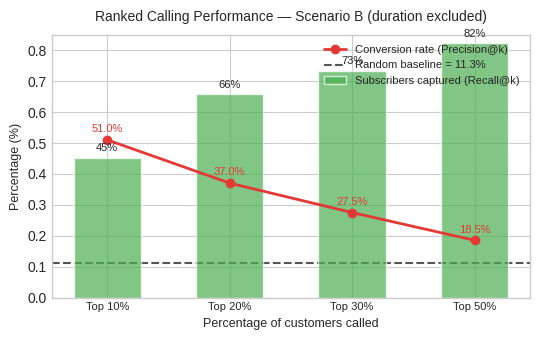

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
#BLOCK 10
# ===================== DỮ LIỆU =====================
# Lấy trực tiếp từ kết quả Top-k đã tính ở phía trên
k_labels = topk_df['Fraction contacted'].tolist()

precision = (
    topk_df['Conversion rate (%)'].to_numpy() / 100
)

recall = (
    topk_df['Subscribers captured (%)'].to_numpy() / 100
)

baseline = y_test.mean()

# ===================== VẼ BIỂU ĐỒ =====================
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(5.5, 3.5))
x = np.arange(len(k_labels))
width = 0.55

# Cột Recall
bars = ax.bar(x, recall, width,
              label='Subscribers captured (Recall@k)',
              color='#4CAF50', alpha=0.7, zorder=2)

# Đường Precision
ax.plot(x, precision, 'o-', color='#E53935', linewidth=2, markersize=6,
        label='Conversion rate (Precision@k)', zorder=3)

# Đường cơ sở
ax.axhline(y=baseline, color='#555555', linestyle='--', linewidth=1.5,
           label=f'Random baseline = {baseline:.1%}', zorder=1)

# Ghi giá trị trên cột
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., h + 0.015,
            f'{h:.0%}', ha='center', va='bottom', fontsize=8)

# Ghi giá trị trên điểm đường
for xi, pi in zip(x, precision):
    ax.text(xi, pi + 0.025, f'{pi:.1%}', ha='center', fontsize=8, color='#E53935')

# Định dạng
ax.set_ylabel('Percentage (%)', fontsize=9)
ax.set_xlabel('Percentage of customers called', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(k_labels, fontsize=8)
ax.set_ylim(0, 0.85)
ax.legend(loc='upper right', fontsize=8)
ax.set_title('Ranked Calling Performance — Scenario B (duration excluded)',
             fontsize=10, pad=10)

plt.tight_layout()

# ===================== LƯU & TẢI TRÊN COLAB =====================
from google.colab import files

filename = 'fig6_ranked_calling.pdf'
plt.savefig(filename, bbox_inches='tight')
print(f'✅ File {filename} đã tạo xong! Đang tải về máy...')
files.download(filename)

plt.show()

In [ ]:

# ============================================================
# BLOCK 11: LƯU KẾT QUẢ & XUẤT FILE
# ============================================================

import os
import json
import joblib
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    average_precision_score,
    f1_score,
    recall_score,
    precision_score
)

# PURPOSE: Lưu kết quả thí nghiệm để viết báo cáo ADY201m.
# WHY: Đảm bảo kết quả CV, Test và mô hình được lưu riêng.
# WARNING: Test chỉ dùng để báo cáo kết quả cuối cùng.

os.makedirs("models", exist_ok=True)


# ============================================================
# 1. TÍNH CÁC METRICS TRÊN TẬP TEST
# ============================================================

pos_label = 1

pr_auc = round(
    average_precision_score(y_test, y_proba_test), 4
)

f1 = round(
    f1_score(y_test, y_pred_test, pos_label=pos_label), 4
)

recall = round(
    recall_score(y_test, y_pred_test, pos_label=pos_label), 4
)

precision = round(
    precision_score(
        y_test, y_pred_test,
        pos_label=pos_label,
        zero_division=0
    ), 4
)

acc = round(
    accuracy_score(y_test, y_pred_test), 4
)

bal_acc = round(
    balanced_accuracy_score(y_test, y_pred_test), 4
)


# ============================================================
# 2. LƯU CROSS-VALIDATION CỦA SCENARIO A VÀ B
# ============================================================

# PURPOSE: Lưu kết quả so sánh 5 mô hình.
# WHY: Đây là kết quả dùng để lựa chọn mô hình bằng CV.
# Không sử dụng Test để xếp hạng mô hình.

cv_A.to_csv(
    "models/cv_A.csv",
    index=False,
    encoding="utf-8-sig"
)

cv_B.to_csv(
    "models/cv_B.csv",
    index=False,
    encoding="utf-8-sig"
)

comp_cv.to_csv(
    "models/comparison_cv_A_B.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 3. LƯU KẾT QUẢ TEST CUỐI CÙNG — SCENARIO B
# ============================================================

# PURPOSE: Ghi nhận kết quả trên dữ liệu chưa dùng để tuning.
# WHY: Scenario B không có duration, phù hợp dự đoán trước cuộc gọi.
#
# WARNING: Không tạo test_A/test_B giả để tránh NameError.

final_test = pd.DataFrame([{
    "Model": best_name,
    "Scenario": "B - Without duration",
    "Threshold": float(chosen_threshold),
    "PR-AUC (AP)": pr_auc,
    "F1": f1,
    "Recall": recall,
    "Precision": precision,
    "Accuracy": acc,
    "Balanced Accuracy": bal_acc
}])

final_test.to_csv(
    "models/final_test_B.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 4. LƯU PHÂN TÍCH TOP-K — RQ3
# ============================================================

# PURPOSE: Lưu hiệu quả ưu tiên gọi khách theo điểm dự đoán.
# WHY: Dùng Precision@k, Recall@k và Lift@k để trả lời RQ3.

topk_df.to_csv(
    "models/topk_results.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 5. LƯU PIPELINE ĐÃ HUẤN LUYỆN
# ============================================================

# PURPOSE: Lưu toàn bộ pipeline gồm feature selection,
# preprocessing, SMOTETomek và mô hình cuối cùng.
#
# WHY: Có thể nạp lại để dự đoán mà không huấn luyện lại.

joblib.dump(
    best_pipe,
    "models/best_model.joblib"
)


# ============================================================
# 6. LƯU CẤU HÌNH TRIỂN KHAI
# ============================================================

deployment_info = {
    "model_name": best_name,
    "scenario": "B",
    "threshold": float(chosen_threshold),
    "input_columns": X_B_tr.columns.tolist(),
    "selected_features": top_features_final,
    "random_seed": SEED
}

with open(
    "models/deployment_info.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        deployment_info,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 7. LƯU METADATA
# ============================================================

meta = {
    "model": best_name,
    "scenario": "B",
    "threshold": round(float(chosen_threshold), 4),
    "pr_auc_test": pr_auc,
    "f1_test": f1,
    "recall_test": recall,
    "precision_test": precision,
    "accuracy_test": acc,
    "balanced_accuracy_test": bal_acc,
    "train_samples": int(len(y_train)),
    "feature_count": int(X_tr_final.shape[1])
}

with open(
    "models/model_meta.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        meta,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 8. IN TÓM TẮT KẾT QUẢ
# ============================================================

print("\n" + "=" * 70)
print("🏆 TÓM TẮT KẾT QUẢ CUỐI CÙNG")
print("=" * 70)

print(f"Mô hình:            {best_name}")
print(f"Kịch bản:           B - Không duration")
print(f"Ngưỡng quyết định:  {chosen_threshold:.4f}")
print(f"PR-AUC (AP):        {pr_auc:.4f}")
print(f"F1 (lớp 1):         {f1:.4f}")
print(f"Recall (lớp 1):     {recall:.4f}")
print(f"Precision (lớp 1):  {precision:.4f}")
print(f"Accuracy:           {acc:.4f}")
print(f"Balanced Accuracy:  {bal_acc:.4f}")

print("=" * 70)

print("\n✅ CÁC FILE ĐÃ LƯU:")
for filename in sorted(os.listdir("models")):
    print(f"   - {filename}")

print("\n🎉 HOÀN THÀNH BLOCK 8!")



🏆 TÓM TẮT KẾT QUẢ CUỐI CÙNG
Mô hình:            LightGBM
Kịch bản:           B - Không duration
Ngưỡng quyết định:  0.6177
PR-AUC (AP):        0.4632
F1 (lớp 1):         0.5068
Recall (lớp 1):     0.5399
Precision (lớp 1):  0.4776
Accuracy:           0.8816
Balanced Accuracy:  0.7325

✅ CÁC FILE ĐÃ LƯU:
   - best_model.joblib
   - comparison_cv_A_B.csv
   - cumulative_gain_B.csv
   - cumulative_gain_B.png
   - cv_A.csv
   - cv_B.csv
   - deployment_info.json
   - figure5b_lightgbm_tuned.png
   - final_20_features_B.csv
   - final_test_B.csv
   - lightgbm_best_params.json
   - lightgbm_tuned_feature_importance.csv
   - lightgbm_tuning_results.csv
   - model_meta.json
   - pr_curve.png
   - topk_analysis.png
   - topk_results.csv

🎉 HOÀN THÀNH BLOCK 8!


In [ ]:

# === ĐÓNG GÓI TOÀN BỘ KẾT QUẢ ADY201m ===

import os
import shutil
from google.colab import files

# Kiểm tra thư mục kết quả
if not os.path.isdir("models"):
    print("Chưa tìm thấy thư mục models.")
    print("Hãy chạy các block xuất kết quả trước.")
else:
    # Liệt kê file thực tế
    print("Các file trong thư mục models:")
    for root, dirs, filenames in os.walk("models"):
        for filename in filenames:
            print(os.path.join(root, filename))

    # Nén thư mục models thành ZIP
    zip_path = shutil.make_archive(
        "ADY201m_Results",
        "zip",
        root_dir=".",
        base_dir="models"
    )

    print("\nĐã tạo:", zip_path)

    # Tải về máy
    files.download(zip_path)


Các file trong thư mục models:
models/cumulative_gain_B.csv
models/lightgbm_best_params.json
models/deployment_info.json
models/cv_B.csv
models/cumulative_gain_B.png
models/topk_analysis.png
models/final_test_B.csv
models/pr_curve.png
models/best_model.joblib
models/lightgbm_tuned_feature_importance.csv
models/cv_A.csv
models/topk_results.csv
models/model_meta.json
models/lightgbm_tuning_results.csv
models/final_20_features_B.csv
models/comparison_cv_A_B.csv
models/figure5b_lightgbm_tuned.png

Đã tạo: /content/ADY201m_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
   import sys, sklearn, imblearn, lightgbm, xgboost, pandas, numpy, scipy, joblib, matplotlib, seaborn
   print(sys.version)
   for m in [sklearn, imblearn, lightgbm, xgboost, pandas, numpy, scipy, joblib, matplotlib, seaborn]:
       print(m.__name__, m.__version__)
   !nproc && free -h | head -2

3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
sklearn 1.6.1
imblearn 0.14.2
lightgbm 4.6.0
xgboost 3.4.1
pandas 2.2.3
numpy 2.4.6
scipy 1.16.3
joblib 1.6.0
matplotlib 3.10.0
seaborn 0.13.2
2
               total        used        free      shared  buff/cache   available
Mem:            12Gi       2.7Gi       7.3Gi       2.9Mi       3.0Gi        10Gi
